# Лабораторная работа 1 — рабочий ноутбук

**ФИО:** Гончар Александр Сергеевич
**Файлы данных:** `data/clients.csv`, `data/transactions.csv`

Этот ноутбук — чистовой рабочий документ, а не черновик. Он должен
исполняться сверху вниз без ошибок на выданном вам **сыром** файле
и на выходе давать очищенную таблицу и `cleaning_log.csv`.

Разделы ниже обязательны, порядок менять не нужно. Внутри раздела
добавляйте столько ячеек, сколько нужно. Если какой-то раздел у вас
пустой — напишите в нём одной строкой, почему.

## 0. Окружение и настройки

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)

RAW_CLIENTS = "data/clients.csv"
RAW_TXN = "data/transactions.csv"

## 1. Загрузка сырых данных

Файлы выгружены разными системами. Убедитесь, что они прочитались
**правильно**: кодировка, разделитель, десятичный разделитель, типы,
даты, идентификаторы.

Пробуем прочитать
файл с разными параметрами. Неверная кодировка дает `UnicodeDecodeError`,
неверный разделитель дает один столбец вместо нескольких.

In [2]:
for path in [RAW_CLIENTS, RAW_TXN]:
    for enc in ["utf-8", "cp1251"]:
        for sep in [",", ";"]:
            try:
                df = pd.read_csv(path, encoding=enc, sep=sep)
                print(path, enc, repr(sep), "- столбцов:", df.shape[1])
            except UnicodeDecodeError:
                print(path, enc, repr(sep), "- ошибка кодировки")

data/clients.csv utf-8 ',' - столбцов: 16
data/clients.csv utf-8 ';' - столбцов: 1
data/clients.csv cp1251 ',' - ошибка кодировки
data/clients.csv cp1251 ';' - ошибка кодировки
data/transactions.csv utf-8 ',' - ошибка кодировки
data/transactions.csv utf-8 ';' - ошибка кодировки
data/transactions.csv cp1251 ',' - столбцов: 1
data/transactions.csv cp1251 ';' - столбцов: 9


`clients.csv` кодировка UTF-8, разделитель ',' (16 столбцов). `transactions.csv` кодировка cp1251,
разделитель ';' (9 столбцов). Но то, что файл открылся в cp1251, еще не значит, что кодировка верная так как
в cp1251 откроется почти любой файл, просто вместо букв может получиться мусор.
Поэтому дальше будем смотреть на сам текст.

Смотрим первые строки transactions и проверяем, что русские слова читаются.

In [3]:
pd.read_csv(RAW_TXN, encoding="cp1251", sep=";", nrows=5)

,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
0,990102,C003921,2023-11-24 09:00:10,"1018,07",RUB,Кафе/рестораны,5812,Карта,успешно
1,990012,C002226,2023-11-25 17:53:53,"454,49",RUB,Продукты,5411,Карта,успешно
2,990027,C000544,2023-11-27 13:30:37,"1194,49",RUB,Продукты,5411,Онлайн-банк,успешно
3,990169,C002702,2023-11-27,"755,99",RUB,Онлайн-сервисы,5815,Карта,успешно
4,990082,C001351,2023-12-12,"1911,83",RUB,Продукты,5411,Карта,успешно


Категории, каналы и статусы читаются как нормальные русские слова,
значит кодировка cp1251 выбрана верно.
Также в amount дробная часть отделена запятой.

Читаем `transactions.csv` без указания десятичного разделителя и смотрим тип amount.

In [4]:
txn_try = pd.read_csv(RAW_TXN, encoding="cp1251", sep=";")
print(txn_try["amount"].dtype, txn_try["amount"].head(3).tolist())

str ['1018,07', '454,49', '1194,49']


Видим, что amount прочитался как текст, так как pandas по умолчанию ждет точку, а в файле запятая. Поэтому указываем `decimal=","`.

In [5]:
txn_try = pd.read_csv(RAW_TXN, encoding="cp1251", sep=";", decimal=",")
print(txn_try["amount"].dtype, txn_try["amount"].head(5).tolist())

float64 [1018.07, 454.49, 1194.49, 755.99, 1911.83]


С `decimal=","` amount стал числом. pandas делает столбец числовым только если смог перевести каждое значение, так что все суммы прочитались правильно.

Итоговое чтение обоих файлов с найденными параметрами.

`client_id`, `txn_id`, `branch_code`, `mcc_code` читаем как текст. Это метки, а не числа и складывать их бессмысленно. У `branch_code` вида '00409' при чтении числом потерялись бы ведущие нули.
Даты pandas сам оставляет текстом, форматы дат в файлах разные, в разделе 3.1 этим займемся.

In [6]:
clients_raw = pd.read_csv(RAW_CLIENTS, dtype={"client_id": str, "branch_code": str})
txn_raw = pd.read_csv(RAW_TXN, encoding="cp1251", sep=";", decimal=",",
                      dtype={"txn_id": str, "client_id": str, "mcc_code": str})

Проверяем результат: `info()` показывает число строк, тип каждого столбца и сколько в нем непустых значений.

In [7]:
clients_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 5690 entries, 0 to 5689
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   client_id           5690 non-null   str    
 1   birth_date          5690 non-null   str    
 2   gender              5690 non-null   str    
 3   city                5690 non-null   str    
 4   segment             5690 non-null   str    
 5   loyalty_tier        5690 non-null   str    
 6   card_type           5690 non-null   str    
 7   registration_date   5690 non-null   str    
 8   card_open_date      5690 non-null   str    
 9   income_source       5690 non-null   str    
 10  monthly_income      5204 non-null   float64
 11  has_mobile_app      5690 non-null   str    
 12  app_last_login      3525 non-null   str    
 13  satisfaction_score  2331 non-null   float64
 14  branch_code         5690 non-null   str    
 15  marketing_opt_in    5690 non-null   str    
dtypes: float64(2), st

In [8]:
txn_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 626169 entries, 0 to 626168
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   txn_id        626169 non-null  str    
 1   client_id     626169 non-null  str    
 2   txn_datetime  626169 non-null  str    
 3   amount        626169 non-null  float64
 4   currency      626169 non-null  str    
 5   category      626169 non-null  str    
 6   mcc_code      626169 non-null  str    
 7   channel       626169 non-null  str    
 8   status        626169 non-null  str    
dtypes: float64(1), str(8)
memory usage: 43.0 MB


Итог загрузки:

`clients.csv` – 5690 строк и 16 столбцов, `transactions.csv` – 626169 строк и 9 столбцов.

Столбцы `amount` и `monthly_income` прочитались как числа (`float64`), а id и даты остались текстом. По `Non-Null Count` видно пропуски в `monthly_income`, `app_last_login` и `satisfaction_score`, их разберем в разделе 3.3.

`satisfaction_score` тоже получился `float64`, хотя оценки целые от 1 до 5, это из-за пропусков. 

## 2. Аудит качества

Здесь вы ничего не исправляете — только находите и измеряете.
Для каждой метрики качества заранее определите знаменатель.

### 2.1. Объём, типы, ключи, единица наблюдения

Собираем короткий паспорт обеих таблиц: объем, типы, ключ и единица наблюдения, то есть что означает одна строка.
По описанию в `clients.csv` одна строка – это один клиент с ключом `client_id`, а в `transactions.csv` одна строка – одна операция с ключом `txn_id`.
Если так, ключ должен быть уникальным. Доля лишних строк считается от числа строк таблицы.

In [9]:
passport = pd.DataFrame({
    "строк": [len(clients_raw), len(txn_raw)],
    "столбцов": [clients_raw.shape[1], txn_raw.shape[1]],
    "числовых столбцов": [clients_raw.select_dtypes("number").shape[1], txn_raw.select_dtypes("number").shape[1]],
    "ключ": ["client_id", "txn_id"],
    "уникальных ключей": [clients_raw["client_id"].nunique(), txn_raw["txn_id"].nunique()],
}, index=["clients.csv", "transactions.csv"])
passport["лишних строк"] = passport["строк"] - passport["уникальных ключей"]
passport["доля лишних, %"] = (passport["лишних строк"] / passport["строк"] * 100).round(1)
passport

,строк,столбцов,числовых столбцов,ключ,уникальных ключей,лишних строк,"доля лишних, %"
clients.csv,5690,16,2,client_id,5635,55,1.0
transactions.csv,626169,9,1,txn_id,624669,1500,0.2


В `clients.csv` 16 столбцов, из них числовых только 2 (`monthly_income` и `satisfaction_score`), в `transactions.csv` из 9 столбцов числовой один – `amount`. Остальное текст.

Ключи не уникальны. В `clients.csv` 5690 строк, но разных `client_id` только 5635, лишних строк 55.
В `transactions.csv` лишних строк 1500.
Значит один клиент или одна операция могут встречаться несколько раз, и единица наблюдения не совпадает с описанием.

### 2.2. Дубли

Начинаем с `clients.csv`. Повтор `client_id` бывает двух видов: полная копия строки (все поля совпадают) или разные записи с одним id.
Первое – техническое дублирование выгрузки, второе – противоречие: непонятно, какая запись верная.

In [10]:
print("лишних строк по client_id:", clients_raw["client_id"].duplicated().sum(), "из", len(clients_raw))
print("из них полных копий строк:", clients_raw.duplicated().sum())

лишних строк по client_id: 55 из 5690
из них полных копий строк: 40


Из 55 повторов 40 – точные копии, их можно просто убрать. А вот у 15 клиентов записи разные, дальше посмотрим, какие поля не совпадают.

In [11]:
clients_dup = clients_raw[clients_raw["client_id"].duplicated(keep=False)]
clients_dup_unique = clients_dup.drop_duplicates()
clients_conflict = clients_dup_unique[clients_dup_unique["client_id"].duplicated(keep=False)]
print("client_id с разными данными в повторах:", clients_conflict["client_id"].nunique())

diff_cols = (clients_conflict.groupby("client_id").nunique(dropna=False) > 1).sum()
diff_cols[diff_cols > 0]

client_id с разными данными в повторах: 15


city       14
segment    10
dtype: int64

Различия только в двух полях: `city` (14 клиентов) и `segment` (10 клиентов). По числам не понять, это опечатки в написании города или разные записи, поэтому смотрим на примеры. 

In [12]:
clients_conflict.sort_values("client_id")[["client_id", "city", "segment"]]

,client_id,city,segment
3322,C001083,Новосибирск,Премиальный
2067,C001083,Новосибирск,Зарплатный
3937,C001632,ЕКАТЕРИНБУРГ,Private
4864,C001632,Санкт-Петербург,Массовый
4711,C002094,Новосибирск,Зарплатный
786,C002094,г.Екатеринбург,Премиальный
1955,C002355,Нижний Новгород,Премиальный
4763,C002355,Казань,Массовый
4369,C002475,г.Екатеринбург,Премиальный
1601,C002475,Казань,Зарплатный


Названия городов в данных записаны по-разному: один и тот же город встречается с разным регистром, сокращениями и с «г.» или без. Даже если считать разные написания одним городом, у большинства из 15 клиентов две записи все равно указывают на разные города, а часто и на разные сегменты. Для этих клиентов настоящие город и сегмент неизвестны.

Один человек может быть записан под разными `client_id`. Проверяем по признакам, которые у человека не меняются: дата рождения, пол, дата прихода в банк и дата открытия карты. Берем по одной строке на `client_id`, чтобы уже найденные повторы не мешали.

In [13]:
stable = ["birth_date", "gender", "registration_date", "card_open_date"]
one_per_id = clients_raw.drop_duplicates("client_id")
print("одних и тех же людей под разными client_id:", one_per_id.duplicated(subset=stable).sum())

одних и тех же людей под разными client_id: 0


Под разными `client_id` нет клиентов с одинаковыми датой рождения, полом и датами регистрации и открытия карты.

Теперь `transactions.csv`, проверяем повторы `txn_id` так же.

In [14]:
print("лишних строк по txn_id:", txn_raw["txn_id"].duplicated().sum(), "из", len(txn_raw))
print("из них полных копий строк:", txn_raw.duplicated().sum())

лишних строк по txn_id: 1500 из 626169
из них полных копий строк: 1259


Из 1500 повторов 1259 – точные копии строк. У остальных 241 записи с одним `txn_id` чем-то отличаются, посмотрим чем они будут отличаться.

In [15]:
txn_dup = txn_raw[txn_raw["txn_id"].duplicated(keep=False)]
txn_dup_unique = txn_dup.drop_duplicates()
txn_conflict = txn_dup_unique[txn_dup_unique["txn_id"].duplicated(keep=False)]
print("txn_id с разными данными в повторах:", txn_conflict["txn_id"].nunique())

txn_diff_cols = (txn_conflict.groupby("txn_id").nunique(dropna=False) > 1).sum()
txn_diff_cols[txn_diff_cols > 0]

txn_id с разными данными в повторах: 241


txn_datetime    241
dtype: int64

Различается только по полю `txn_datetime`. Проверяем, как именно они различаются.

In [16]:
pairs = txn_conflict.groupby("txn_id")["txn_datetime"]
print("пар, где дата одна и та же:", (pairs.agg(lambda s: s.str[:10].nunique()) == 1).sum())
print("пар, где в одной записи только дата без времени:", (pairs.agg(lambda s: s.str.len().min()) == 10).sum())
txn_conflict.sort_values("txn_id").head(4)

пар, где дата одна и та же: 241
пар, где в одной записи только дата без времени: 241


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
208,100202,C003891,2024-01-01 11:56:08,495.24,RUB,Продукты,5411,Карта,успешно
209,100202,C003891,2024-01-01,495.24,RUB,Продукты,5411,Карта,успешно
3673,103657,C002052,2024-01-05,783.06,RUB,Продукты,5411,Карта,успешно
3674,103657,C002052,2024-01-05 14:51:41,783.06,RUB,Продукты,5411,Карта,успешно


Во всех 241 парах дата одна и та же, просто в одной записи время есть, а в другой только дата. Остальные поля, включая сумму, совпадают. Значит это одна и та же операция, записанная дважды. У нас выходит 1259 точных копий и 241 копия, которые отличаются только форматом даты.

### 2.3. Соответствие данных описанию полей из задания

Сначала категориальные поля. Для тех, у которых в описании задания перечислены значения, проверяем, нет ли в данных других значений. Считаем по сырым строкам, дубли еще не убраны.

In [17]:
expected = {
    "segment": ["Массовый", "Зарплатный", "Премиальный", "Private"],
    "loyalty_tier": ["Базовый", "Серебро", "Золото", "Платина"],
    "card_type": ["Дебетовая", "Кредитная", "Премиальная"],
}
for col, values in expected.items():
    extra = clients_raw.loc[~clients_raw[col].isin(values), col]
    print(col, "| значений не из описания:", len(extra))

expected_txn = {
    "channel": ["Карта", "Токен", "СБП", "Онлайн-банк"],
    "status": ["успешно", "отклонено", "возврат"],
}
for col, values in expected_txn.items():
    extra = txn_raw.loc[~txn_raw[col].isin(values), col]
    print(col, "| значений не из описания:", len(extra))

segment | значений не из описания: 0
loyalty_tier | значений не из описания: 0
card_type | значений не из описания: 0
channel | значений не из описания: 0
status | значений не из описания: 0


В `segment`, `loyalty_tier`, `card_type`, `channel` и `status` все значения совпадают с описанием.

Для остальных полей значения в описании не перечислены, поэтому смотрим на них через `value_counts()`.

In [18]:
for col in ["gender", "has_mobile_app", "marketing_opt_in", "income_source"]:
    display(clients_raw[col].value_counts(dropna=False))

gender
Ж    2859
М    2831
Name: count, dtype: int64

has_mobile_app
Да     3525
Нет    2165
Name: count, dtype: int64

marketing_opt_in
Да     5022
Нет     668
Name: count, dtype: int64

income_source
Зарплата в нашем банке     2547
Зарплата в другом банке    1599
Не указан                  1544
Name: count, dtype: int64

`gender`, `has_mobile_app` и `marketing_opt_in` принимают по два значения, тут все чисто.
В `income_source` есть значение `Не указан` – 1544 строки из 5690. Это пропуск, просто вместо пустой ячейки в ней стоит текст, поэтому `info()` считает эти строки заполненными, хотя источник дохода в них неизвестен.

В описании сказано, что `category` – одна из девяти категорий. Проверяем.

In [19]:
txn_raw["category"].value_counts()

category
Продукты               164934
Транспорт               65912
Одежда и обувь          65275
АЗС                     58023
Кафе и рестораны        51038
Развлечения и досуг     48162
Аптеки                  45391
Онлайн-сервисы          44112
Связь и интернет        29305
Связь и Интернет        19592
Кафе/рестораны          17226
кафе и рестораны        17199
Name: count, dtype: int64

Категорий 12, а не 9. Лишние появились из-за разного написания. Если их объединить, то у нас получится как раз 9.

Про валюту в описании ничего не сказано, смотрим, какие значения есть.

In [20]:
txn_raw["currency"].value_counts()

currency
RUB    623636
EUR      1283
USD      1250
Name: count, dtype: int64

Кроме рублей есть операции в `EUR` и `USD`. Суммы в разных валютах нельзя просто складывать, а курсов в данных нет.

По описанию `city` – город проживания. Смотрим, как записаны города. 

In [21]:
print("разных значений city:", clients_raw["city"].nunique())
clients_raw["city"].value_counts()

разных значений city: 17


city
Москва                1129
Новосибирск            681
Санкт-Петербург        657
Казань                 563
Нижний Новгород        534
Екатеринбург           526
г. Новосибирск         224
МОСКВА                 183
г. Москва              178
 москва                171
Н. Новгород            162
казань                 142
г. Санкт-Петербург     131
Санкт Петербург        113
СПб                    109
г.Екатеринбург          98
ЕКАТЕРИНБУРГ            89
Name: count, dtype: int64

Разных значений 17, а городов на самом деле 6 .Один и тот же город записан по-разному: разный регистр, приставка, пробел в начале, сокращения, запись без дефиса.

По описанию `mcc_code` соответствует категории. Смотрим таблицу сопряженности: сколько операций в каждой паре категории и кода.

In [22]:
pd.crosstab(txn_raw["category"], txn_raw["mcc_code"])

mcc_code,4111,4814,5411,5541,5651,5812,5815,5912,7832
category,,,,,,,,,
АЗС,29,20,23,57854,22,24,15,17,19
Аптеки,18,15,7,19,11,14,21,45277,9
Кафе и рестораны,12,12,18,16,18,50913,22,10,17
Кафе/рестораны,3,9,7,5,4,17184,8,3,3
Одежда и обувь,22,24,33,17,65106,18,22,17,16
Онлайн-сервисы,11,9,14,18,16,8,44013,10,13
Продукты,53,61,164482,53,58,53,66,57,51
Развлечения и досуг,20,15,16,16,19,14,8,14,48040
Связь и Интернет,8,19540,4,8,8,7,7,7,3


У каждой категории есть свой основной код, в нем почти все операции, а разные написания одной категории имеют один и тот же код. Но в каждой строке есть небольшие числа и в чужих столбцах – это операции, где код не совпадает с категорией. Считаем, сколько их.

In [23]:
main_mcc = txn_raw.groupby("category")["mcc_code"].agg(lambda s: s.mode()[0])
mcc_mismatch = txn_raw["mcc_code"] != txn_raw["category"].map(main_mcc)
print("операций, где mcc_code не совпадает с основным кодом категории:", mcc_mismatch.sum(), "из", len(txn_raw))

операций, где mcc_code не совпадает с основным кодом категории: 1645 из 626169


Таких операций 1645 из 626169. Это расхождение описания с фактом: код не всегда соответствует категории. По самим данным нельзя сказать, что из двух записано неверно – категория или код.

Теперь числовые поля. Начинаем с суммы операции `amount`.

In [24]:
txn_raw["amount"].describe().round(2)

count    626169.00
mean       1852.85
std        2679.21
min      -47261.19
25%         465.48
50%        1065.48
75%        2242.89
max      164155.52
Name: amount, dtype: float64

Минимум отрицательный (-47261.19). Проверяем, у каких операций сумма меньше нуля.

In [25]:
print("операций с отрицательной суммой:", (txn_raw["amount"] < 0).sum(), "из", len(txn_raw))
print("из них со статусом возврат:", ((txn_raw["amount"] < 0) & (txn_raw["status"] == "возврат")).sum())
print("всего возвратов:", (txn_raw["status"] == "возврат").sum())

операций с отрицательной суммой: 7625 из 626169
из них со статусом возврат: 7625
всего возвратов: 7625


Все 7625 отрицательных сумм – возвраты, и все возвраты записаны с минусом. Возврат уменьшает траты клиента. Еще в `amount` вместе лежат и рубли, и евро, и доллары, поэтому `describe()` по всему столбцу дает только общее представление.

По описанию `monthly_income` – ежемесячный доход в рублях.

In [26]:
clients_raw["monthly_income"].describe().round(0)

count       5204.0
mean       95083.0
std        84636.0
min         -999.0
25%        52600.0
50%        72900.0
75%       108400.0
max      1135600.0
Name: monthly_income, dtype: float64

Минимум -999, а отрицательного дохода не бывает. Смотрим подробнее на маленькие значения.

In [27]:
income = clients_raw["monthly_income"]
ranges = pd.cut(income, [-1000, 0, 1000, 10000, income.max()],
                labels=["0 и меньше", "от 0 до 1000", "от 1000 до 10000", "больше 10000"])
ranges.value_counts(sort=False, dropna=False)

monthly_income
0 и меньше            54
от 0 до 1000         172
от 1000 до 10000       0
больше 10000        4978
NaN                  486
Name: count, dtype: int64

Таблица показывает, что есть две подозрительные группы: 54 строки с доходом 0 и меньше и 172 строки с доходом меньше 1000 рублей в месяц, причем между 1000 и 10000 нет ни одного значения. Смотрим, какие значения в каждой группе.

In [28]:
print("разные значения среди дохода 0 и меньше:", income[income <= 0].unique().astype(int))

разные значения среди дохода 0 и меньше: [-999]


Во всех 54 строках доход равен ровно -999. Если бы это были ошибки ввода, числа были бы разные, а одно и то же круглое значение у всех – это условный код «нет данных». Значит это не доход, а еще один скрытый пропуск.

In [29]:
income[(income > 0) & (income < 1000)].describe().round(1)

count    172.0
mean      96.5
std       77.1
min       17.9
25%       57.3
50%       77.4
75%      111.6
max      639.1
Name: monthly_income, dtype: float64

Эти 172 значения лежат от 17.9 до 639.1, медиана 77.4. Доход 77 рублей в месяц не бывает, а медиана всего дохода 72900 рублей, то есть 72.9 тысячи. Похоже, у этих клиентов доход записан в тысячах рублей, а не в рублях, как сказано в описании. На это же указывает пустой промежуток от 1000 до 10000.

По описанию `satisfaction_score` – оценка от 1 до 5.

In [30]:
clients_raw["satisfaction_score"].value_counts(dropna=False).sort_index()

satisfaction_score
1.0     298
2.0     464
3.0     447
4.0     471
5.0     651
NaN    3359
Name: count, dtype: int64

Все оценки от 1 до 5, других значений нет. Пропусков 3359 из 5690, то есть оценки нет больше чем у половины строк.

Теперь рассмотрим даты. Форматы в описании не указаны. Разбираем каждую дату клиентов с явным форматом и считаем, сколько значений не разобралось. 

In [31]:
date_formats = {"birth_date": "%Y-%m-%d", "registration_date": "%d.%m.%Y",
                "card_open_date": "%d.%m.%Y", "app_last_login": "%Y-%m"}
for col, fmt in date_formats.items():
    d = pd.to_datetime(clients_raw[col], format=fmt, errors="coerce")
    print(col, "| не разобралось:", (d.isna() & clients_raw[col].notna()).sum(),
          "| от", d.min().date(), "до", d.max().date())

birth_date | не разобралось: 0 | от 1936-07-23 до 2002-04-27
registration_date | не разобралось: 0 | от 2010-02-16 до 2025-03-10
card_open_date | не разобралось: 0 | от 2016-01-01 до 2025-05-16
app_last_login | не разобралось: 0 | от 2024-01-01 до 2025-06-01


Все даты клиентов разобрались, но записаны в разных форматах. Все даты не позже 30.06.2025, на которую составлен справочник.

В `txn_datetime` у части операций есть время, а у части только дата. Разбираем с форматом `ISO8601`, он понимает оба варианта, и сверяем с периодом из описания.

In [32]:
txn_dt = pd.to_datetime(txn_raw["txn_datetime"], format="ISO8601", errors="coerce")
no_time = txn_raw["txn_datetime"].str.len() == 10
print("не разобралось:", txn_dt.isna().sum())
print("операций без времени:", no_time.sum(), "из", len(txn_raw))
print("самая ранняя:", txn_dt.min(), "| самая поздняя:", txn_dt.max())
print("раньше 2024-01-01:", (txn_dt < "2024-01-01").sum())
print("позже 2025-06-30:", (txn_dt >= "2025-07-01").sum())

не разобралось: 0
операций без времени: 50087 из 626169
самая ранняя: 2023-11-24 09:00:10 | самая поздняя: 2026-08-04 12:27:10
раньше 2024-01-01: 6
позже 2025-06-30: 81


Все даты разобрались. 50087 операций из 626169 записаны без времени. По описанию данные охватывают 2024-01-01 – 2025-06-30, но есть 6 операций раньше и 81 позже, вплоть до августа 2026 года, то есть позже даты, на которую составлен справочник. Описание с этим не совпадает.

Проверяем, не сосредоточены ли операции без времени в каком-то одном месяце. Доля считается от всех операций месяца.

In [33]:
(no_time.groupby(txn_dt.dt.to_period("M")).mean() * 100).round(1).loc["2024-01":"2025-06"]

txn_datetime
2024-01    7.7
2024-02    8.2
2024-03    8.2
2024-04    7.9
2024-05    8.0
2024-06    8.1
2024-07    7.8
2024-08    7.9
2024-09    8.1
2024-10    8.1
2024-11    7.9
2024-12    8.2
2025-01    7.8
2025-02    7.9
2025-03    8.0
2025-04    8.2
2025-05    7.9
2025-06    7.8
Freq: M, Name: txn_datetime, dtype: float64

В каждом месяце периода без времени от 7.7% до 8.2% операций, то есть время пропадает равномерно, а не в каком-то одном месяце. Дата у этих операций есть, поэтому для подсчета по месяцам это не мешает.

Дальше рассмотрим логику между полями. Проверяем то, что должно выполняться по смыслу: карту не могли открыть раньше прихода в банк, клиент не мог прийти в банк слишком рано по возрасту (свою карту можно получить с 14 лет), последний вход в приложение не может быть раньше регистрации, а у клиентов без приложения не должно быть даты входа.

In [34]:
birth = pd.to_datetime(clients_raw["birth_date"], format="%Y-%m-%d")
reg = pd.to_datetime(clients_raw["registration_date"], format="%d.%m.%Y")
card_open = pd.to_datetime(clients_raw["card_open_date"], format="%d.%m.%Y")
last_login = pd.to_datetime(clients_raw["app_last_login"], format="%Y-%m")
age_at_reg = (reg - birth).dt.days / 365.25

print("карта открыта раньше прихода в банк:", (card_open < reg).sum())
print("пришли в банк младше 14 лет:", (age_at_reg < 14).sum())
print("последний вход в приложение раньше месяца регистрации:", (last_login < reg.dt.to_period("M").dt.to_timestamp()).sum())
print("нет приложения, но есть дата входа:", ((clients_raw["has_mobile_app"] == "Нет") & last_login.notna()).sum())
print("есть приложение, но нет даты входа:", ((clients_raw["has_mobile_app"] == "Да") & last_login.isna()).sum())

карта открыта раньше прихода в банк: 0
пришли в банк младше 14 лет: 4
последний вход в приложение раньше месяца регистрации: 25
нет приложения, но есть дата входа: 0
есть приложение, но нет даты входа: 0


Карт, открытых раньше регистрации, нет. Но 4 клиента пришли в банк младше 14 лет, а у 25 клиентов последний вход в приложение раньше, чем они вообще стали клиентами банка. Пропуски в `app_last_login` есть только у клиентов без приложения.

По описанию `transactions.csv` – операции по картам. Но в пояснении к каналам сказано, что `СБП` – перевод по Системе быстрых платежей, а `Онлайн-банк` – операция в интернет-банке, то есть это не оплата картой. Смотрим, сколько операций в каждом канале. Доля считается от всех 626169 операций.

In [35]:
channel_counts = txn_raw["channel"].value_counts()
pd.DataFrame({"операций": channel_counts, "доля, %": (channel_counts / len(txn_raw) * 100).round(1)})

,операций,"доля, %"
channel,,
Карта,321575,51.4
СБП,107549,17.2
Токен,102000,16.3
Онлайн-банк,95045,15.2


Оплаты картой – это `Карта` (пластик) и `Токен` (телефон или часы). А `СБП` и `Онлайн-банк` занимают 17.2% и 15.2% операций, то есть в файле есть не только операции по картам, как сказано в описании.

### 2.4. Связь между таблицами

Проверяем, совпадают ли клиенты в двух таблицах. Объединяем списки `client_id` с `indicator=True`: он показывает, где нашелся клиент – только в операциях (`left_only`), только в справочнике (`right_only`) или в обеих таблицах (`both`).

In [36]:
ids = txn_raw[["client_id"]].drop_duplicates().merge(
    clients_raw[["client_id"]].drop_duplicates(), how="outer", indicator=True)
ids["_merge"].value_counts()

_merge
both          5625
left_only      365
right_only      10
Name: count, dtype: int64

У 5625 клиентов есть и операции, и запись в справочнике. 365 клиентов есть в операциях, но их нет в справочнике, а 10 клиентов из справочника не сделали ни одной операции.

Смотрим на клиентов не из справочника: сколько у них операций и когда была их последняя операция.

In [37]:
unknown_ids = ids.loc[ids["_merge"] == "left_only", "client_id"]
unknown = txn_raw["client_id"].isin(unknown_ids)
print("операций у клиентов не из справочника:", unknown.sum(), "из", len(txn_raw))
txn_dt[unknown].groupby(txn_raw.loc[unknown, "client_id"]).max().dt.to_period("Q").value_counts().sort_index()

операций у клиентов не из справочника: 32642 из 626169


txn_datetime
2024Q3      1
2024Q4    179
2025Q1    181
2025Q2      3
2025Q3      1
Freq: Q-DEC, Name: count, dtype: int64

У этих 365 клиентов 32642 операции. Последняя операция почти у всех в конце 2024 – начале 2025 года: у 179 в 4 квартале 2024 и у 181 в 1 квартале 2025. Справочник – это действующие клиенты на 30.06.2025, поэтому похоже, что это клиенты, которые ушли из банка. Операции у них есть в базовом периоде, а потом прекращаются, поэтому их уход может выглядеть как падение активности.

**Выводы по аудиту.** Перечислите найденное: что это, сколько строк,
насколько это мешает решить задачу.

Сильнее всего мешают три вещи. В операциях есть 365 клиентов, которых нет в справочнике действующих клиентов, у них 32642 операции из 626169. Последняя операция у них почти у всех в конце 2024 – начале 2025 года, поэтому похоже, что они ушли из банка, и если их не отделить, их уход будет выглядеть как падение активности. Операции через `СБП` и `Онлайн-банк` (17.2% и 15.2% от 626169 операций, вместе около трети) не являются оплатой картой, хотя файл описан как операции по картам, поэтому от выбора каналов зависит сама метрика. Наконец, 1500 операций записаны дважды – это завышает активность.

Мешают группировать, но легко исправляются: города записаны 17 способами вместо 6, категорий 12 вместо 9, у 40 строк клиентов есть полные копии, а у 15 клиентов две разные записи с разными городом или сегментом.

Касаются отдельных полей: доход пустой у 486 строк из 5690, равен -999 у 54 и похож на записанный в тысячах у 172, источник дохода `Не указан` у 1544, оценки качества нет у 3359. Это важно, только если эти поля войдут в правила групп. Еще есть операции в валюте (1283 в `EUR` и 1250 в `USD`) и операции вне периода из описания (6 раньше и 81 позже) – их мало.

Мелочи, на выводы почти не влияют: 1645 операций, где код торговой точки не совпадает с категорией, 4 клиента, которые пришли в банк младше 14 лет, и 25 клиентов со входом в приложение раньше регистрации.

## 3. Препроцессинг

На каждое изменение — строка в журнале (раздел 4). Решение «оставить
как есть» тоже является решением и тоже попадает в журнал.

### 3.1. Типы, даты, числа

Все исправления делаем на копиях, сырые данные не меняем так мы будем сравнивать, что было и что стало. Заводим журнал: каждое решение, которое меняет данные, записываем функцией `log_change`.

In [38]:
clients = clients_raw.copy()
txn = txn_raw.copy()

log_rows = []


def log_change(field, issue, scope, n_rows, value_before, action, value_after, rationale):
    log_rows.append({"field": field, "issue": issue, "scope": scope, "n_rows": n_rows,
                     "value_before": value_before, "action": action,
                     "value_after": value_after, "rationale": rationale})

Даты клиентов записаны в разных форматах. Переводим их в тип дата с теми же явными форматами, что что задали в 2.3. `app_last_login` хранит только месяц, поэтому превращается в первое число месяца.

In [39]:
for col, fmt in date_formats.items():
    clients[col] = pd.to_datetime(clients[col], format=fmt)

log_change("birth_date, registration_date, card_open_date, app_last_login",
           "даты записаны текстом в трех разных форматах", "все строки clients", len(clients),
           "'1972-01-20', '21.03.2022', '2024-04'", "исправлено", "тип дата",
           "форматы заданы явно, все значения разобрались без ошибок")
clients[list(date_formats)].dtypes

birth_date           datetime64[us]
registration_date    datetime64[us]
card_open_date       datetime64[us]
app_last_login       datetime64[us]
dtype: object

Дату операции тоже переводим.

In [40]:
txn["txn_datetime"] = pd.to_datetime(txn["txn_datetime"], format="ISO8601")

log_change("txn_datetime", "дата записана текстом, у части операций нет времени", "все строки transactions",
           len(txn), "'2024-01-01 11:56:08', '2024-01-01'", "исправлено", "тип дата-время, без времени -> 00:00:00",
           "формат ISO8601 понимает оба варианта, все значения разобрались (проверено в 2.3)")
print("тип txn_datetime:", txn["txn_datetime"].dtype)

тип txn_datetime: datetime64[us]


Доход. Значение -999 скрытый пропуск, а не доход, поэтому заменяем его на пропуск.

In [41]:
is_code = clients["monthly_income"] == -999
clients.loc[is_code, "monthly_income"] = np.nan

log_change("monthly_income", "код -999 вместо дохода", "monthly_income == -999", is_code.sum(),
           -999, "заменено на пропуск", "NaN",
           "доход меньше нуля и одинаковый у всех 54 строк – это скрытый пропуск")
print("заменено на пропуск:", is_code.sum())

заменено на пропуск: 54


Доходы меньше 1000 рублей в месяц выглядят как записанные в тысячах: после них сразу идет большой разрыв до обычных доходов. Умножаем их на 1000 и проверяем, станут ли они похожи на доходы остальных клиентов.

In [42]:
in_thousands = (clients["monthly_income"] > 0) & (clients["monthly_income"] < 1000)
clients.loc[in_thousands, "monthly_income"] = clients.loc[in_thousands, "monthly_income"] * 1000

log_change("monthly_income", "доход записан в тысячах рублей", "0 < monthly_income < 1000", in_thousands.sum(),
           "17.9 – 639.1", "исправлено", "17900 – 639100",
           "между 1000 и 10000 нет ни одного значения, медиана 77.4 против 72900 у остальных – тот же доход в тысячах")
print("умножено на 1000:", in_thousands.sum())
clients.loc[in_thousands, "monthly_income"].describe().round(0)

умножено на 1000: 172


count       172.0
mean      96451.0
std       77055.0
min       17900.0
25%       57275.0
50%       77350.0
75%      111575.0
max      639100.0
Name: monthly_income, dtype: float64

После умножения эти доходы лежат от 17900 до 639100, медиана 77350 как и у остальных клиентов Предположение про тысячи подтверждается.

### 3.2. Категориальные признаки

Приводим названия городов к одному виду.

In [43]:
city_map = {
    "г. москва": "москва",
    "спб": "санкт-петербург",
    "санкт петербург": "санкт-петербург",
    "г. санкт-петербург": "санкт-петербург",
    "г. новосибирск": "новосибирск",
    "г.екатеринбург": "екатеринбург",
    "н. новгород": "нижний новгород",
}
city_before = clients["city"].copy()
clients["city"] = clients["city"].str.strip().str.lower().replace(city_map).str.title()

log_change("city", "один город записан по-разному", "все строки clients", (city_before != clients["city"]).sum(),
           "' москва', 'МОСКВА', 'г. Москва', 'СПб'", "исправлено", "6 городов: 'Москва', 'Санкт-Петербург' и т.д.",
           "это разные написания одного города, смысл не меняется")
print("изменено строк:", (city_before != clients["city"]).sum())
clients["city"].value_counts()

изменено строк: 1600


city
Москва             1661
Санкт-Петербург    1010
Новосибирск         905
Екатеринбург        713
Казань              705
Нижний Новгород     696
Name: count, dtype: int64

Объединяем одинаковые категории, записанные по-разному.

In [44]:
category_map = {
    "Кафе/рестораны": "Кафе и рестораны",
    "кафе и рестораны": "Кафе и рестораны",
    "Связь и Интернет": "Связь и интернет",
}
category_changed = txn["category"].isin(list(category_map))
txn["category"] = txn["category"].replace(category_map)

log_change("category", "одна категория записана по-разному", "category in " + str(list(category_map)),
           category_changed.sum(), "'Кафе/рестораны', 'кафе и рестораны', 'Связь и Интернет'", "исправлено",
           "'Кафе и рестораны', 'Связь и интернет'", "разные написания одной категории, у них один и тот же mcc_code")
print("изменено строк:", category_changed.sum(), "| категорий:", txn["category"].nunique())

изменено строк: 54017 | категорий: 9


Категорий стало 9. Несовпадения `mcc_code` с категорией оставляем как есть их у нас мало мало, а для анализа берем `category`. Это тоже решение, записываем его в журнал.

In [45]:
log_change("mcc_code", "код не совпадает с основной категорией", "mcc_code != основной код категории",
           mcc_mismatch.sum(), "например 'АЗС' с кодом 5411", "оставлено", "без изменений",
           "мало (1645 из 626169), в анализе используется category, что верно – код или категория – по данным не понять")

`income_source = Не указан` – скрытый пропуск, заменяем его на настоящий пропуск, чтобы он не считался отдельным источником дохода. 

In [46]:
not_given = clients["income_source"] == "Не указан"
clients.loc[not_given, "income_source"] = np.nan

log_change("income_source", "значение «Не указан» вместо источника дохода", "income_source == 'Не указан'",
           not_given.sum(), "Не указан", "заменено на пропуск", "NaN",
           "это отметка об отсутствии данных, а не источник дохода")
print("заменено на пропуск:", not_given.sum())

заменено на пропуск: 1544


`has_mobile_app` и `marketing_opt_in` – да/нет. Переводим их в `True` и `False`, так их будет удобнее считать и фильтровать.

In [47]:
for col in ["has_mobile_app", "marketing_opt_in"]:
    clients[col] = clients[col].map({"Да": True, "Нет": False})

log_change("has_mobile_app, marketing_opt_in", "да/нет записано текстом", "все строки clients", len(clients),
           "'Да', 'Нет'", "исправлено", "True, False", "смысл не меняется, так проще фильтровать")
clients[["has_mobile_app", "marketing_opt_in"]].value_counts(dropna=False)

has_mobile_app  marketing_opt_in
True            True                3103
False           True                1919
True            False                422
False           False                246
Name: count, dtype: int64

Пустых значений не появилось, значит других вариантов, кроме `Да` и `Нет`, не было.

У loyalty_tier есть порядок. Задаем его явно, иначе pandas отсортирует уровни по алфавиту.

In [48]:
loyalty_order = ["Базовый", "Серебро", "Золото", "Платина"]
clients["loyalty_tier"] = pd.Categorical(clients["loyalty_tier"], categories=loyalty_order, ordered=True)

log_change("loyalty_tier", "порядковая шкала записана текстом", "все строки clients", len(clients),
           "'Базовый', 'Серебро', 'Золото', 'Платина'", "исправлено", "упорядоченная категория",
           "уровни лояльности упорядочены, порядок задан явно")
clients["loyalty_tier"].value_counts(sort=False)

loyalty_tier
Базовый    2858
Серебро    1505
Золото     1013
Платина     314
Name: count, dtype: int64

### 3.3. Пропуски

Для каждого поля с пропусками: доля, предположение о механизме, решение.

Сколько пропусков осталось после 3.1 и 3.2. Сюда уже входят скрытые пропуски: -999 в доходе и `Не указан` в источнике дохода. 

In [49]:
missing = clients.isna().sum()
missing = missing[missing > 0].to_frame("пропусков")
missing["из"] = len(clients)
missing["доля, %"] = (missing["пропусков"] / len(clients) * 100).round(1)
print("пропусков в transactions:", txn.isna().sum().sum())
missing

пропусков в transactions: 0


,пропусков,из,"доля, %"
income_source,1544,5690,27.1
monthly_income,540,5690,9.5
app_last_login,2165,5690,38.0
satisfaction_score,3359,5690,59.0


Чтобы понять механизм пропуска, сравниваем долю пропусков в разных группах клиентов. Если пропуски случайные, доля будет примерно одинаковой во всех группах, а если зависит от группы – пропуск связан с этим признаком. Доля считается внутри каждой группы: например, от всех клиентов массового сегмента.

In [50]:
missing_cols = ["monthly_income", "income_source", "satisfaction_score"]
is_missing = clients[missing_cols].isna()
display((is_missing.groupby(clients["segment"]).mean() * 100).round(1))
(is_missing.groupby(clients["loyalty_tier"]).mean() * 100).round(1)

,monthly_income,income_source,satisfaction_score
segment,,,
Private,6.6,29.2,31.9
Зарплатный,5.1,4.9,59.8
Массовый,12.0,40.1,64.6
Премиальный,9.8,24.0,47.4


,monthly_income,income_source,satisfaction_score
loyalty_tier,,,
Базовый,9.8,31.0,68.1
Серебро,8.8,23.1,66.5
Золото,10.1,23.7,29.7
Платина,8.3,22.3,35.7


`monthly_income`: доход не указан у 12.0% массового сегмента и только у 5.1% зарплатного. Зарплату зарплатных клиентов банк видит сам, а остальные указывают доход со своих слов и чаще его не называют. Пропуск зависит от сегмента, который известен, – это MAR (случайный при условии других признаков).

`income_source`: та же картина, но сильнее – 40.1% у массового сегмента и 4.9% у зарплатного. Тоже MAR.

`satisfaction_score`: оценки нет у 68.1% клиентов уровня `Базовый` и 66.5% `Серебро`, но только у 29.7% `Золото` и 35.7% `Платина`. Опрос чаще проходят клиенты с высоким уровнем лояльности, поэтому это MAR. Может быть и MNAR, если недовольные клиенты чаще отказываются от опроса, но по данным это не проверить.

`app_last_login`: пропуск ровно у клиентов без приложения. Это не потеря данных, а неприменимое значение, так как входить некуда.

Наше решение – это ничего не заполнять. Активность будем считать по операциям, а в них пропусков нет. Заполнять доход медианой нельзя пропуски зависят от сегмента, а одно значение для всех сожмет разброс и сдвинет доход массового сегмента. `satisfaction_score` – порядковая шкала, и заполнять ее средним бессмысленно. Для групп эти поля используем только там, где значение известно. Решения записываем в журнал.

In [51]:
for col, mech, why in [
    ("monthly_income", "MAR: чаще не указан у массового сегмента",
     "в метрике не участвует, заполнение одним значением сожмет разброс и сдвинет доход массового сегмента"),
    ("income_source", "MAR: чаще не указан у массового сегмента",
     "в метрике не участвует, заполнить по данным нечем"),
    ("satisfaction_score", "MAR или MNAR: чаще нет у уровней Базовый и Серебро",
     "порядковая шкала, среднее для нее не считается, ответившие не представляют всех клиентов"),
    ("app_last_login", "неприменимо: у клиента нет приложения",
     "значения не может быть, пропуск сам по себе означает отсутствие приложения"),
]:
    log_change(col, "пропуски, механизм " + mech, col + " is NaN", clients[col].isna().sum(),
               "NaN", "оставлено", "NaN", why)
print("записей в журнале:", len(log_rows))

записей в журнале: 14


### 3.4. Выбросы

Обнаружение и решение — это два разных шага. Сначала первый, потом второй.

**Шаг 1. Обнаружение.** Начинаем с сумм операций. Берем только рублевые суммы больше нуля: операции в валюте в другом масштабе, а возвраты отрицательные по смыслу. Ищем кандидатов в выбросы правилом межквартильного размаха (МКР) с множителями 1.5 и 3 и смотрим, сколько операций выше 99.9-го процентиля.

In [52]:
rub = txn.loc[(txn["currency"] == "RUB") & (txn["amount"] > 0), "amount"]
q1, q3 = rub.quantile([0.25, 0.75])
iqr = q3 - q1
print("операций:", len(rub), "| Q1:", round(q1, 2), "| медиана:", round(rub.median(), 2), "| Q3:", round(q3, 2))
for k in [1.5, 3]:
    upper = q3 + k * iqr
    print(f"граница Q3 + {k} МКР: {upper:.2f} | операций выше: {(rub > upper).sum()} ({(rub > upper).mean() * 100:.1f}% от {len(rub)})")
p999 = rub.quantile(0.999)
print(f"99.9-й процентиль: {p999:.2f} | операций выше: {(rub > p999).sum()}")

операций: 616034 | Q1: 490.25 | медиана: 1090.26 | Q3: 2274.34
граница Q3 + 1.5 МКР: 4950.49 | операций выше: 50213 (8.2% от 616034)
граница Q3 + 3 МКР: 7626.63 | операций выше: 21498 (3.5% от 616034)
99.9-й процентиль: 26160.75 | операций выше: 617


Правило 1.5 МКР отмечает 8.2% из 616034 рублевых операций – слишком много, чтобы считать их выбросами. У сумм естественный длинный хвост. Даже с множителем 3 остается 3.5% из них. Смотрим на самые крупные операции.

Но сначала проверяем, что дело действительно в длинном хвосте. Если распределение сильно скошено, правило МКР применяют к логарифму сумм. Логарифм сжимает хвост, и правило начинает искать только по настоящему далекие значения.

In [53]:
log_rub = np.log10(rub)
lq1, lq3 = log_rub.quantile([0.25, 0.75])
liqr = lq3 - lq1
log_low, log_high = lq1 - 1.5 * liqr, lq3 + 1.5 * liqr
outside = (log_rub < log_low) | (log_rub > log_high)
print(f"асимметрия сумм: {rub.skew():.2f} – после логарифма {log_rub.skew():.2f}")
print(f"правило 1.5 МКР по логарифму: {outside.mean() * 100:.1f}% из {len(rub)} операций вместо {(rub > q3 + 1.5 * iqr).mean() * 100:.1f}%")
print(f"границы на исходной шкале: от {10 ** log_low:.2f} до {10 ** log_high:.2f} руб. | ниже: {(log_rub < log_low).sum()} | выше: {(log_rub > log_high).sum()}")

асимметрия сумм: 5.25 – после логарифма -0.47
правило 1.5 МКР по логарифму: 2.1% из 616034 операций вместо 8.2%
границы на исходной шкале: от 49.06 до 22725.55 руб. | ниже: 11835 | выше: 1026


После логарифма суммы распределены почти симметрично (асимметрия -0.47 вместо 5.25), и правило 1.5 МКР отмечает уже 2.1% из тех же 616034 операций, а не 8.2%. Значит большая часть выбросов на исходной шкале – это просто длинный хвост. Сверху за границей остается 1026 операций дороже 22725.55 рублей, а снизу 11835 операций дешевле 49.06 рублей, это мелкие покупки.

In [54]:
txn.nlargest(10, "amount")[["client_id", "txn_datetime", "amount", "currency", "category", "channel", "status"]]

,client_id,txn_datetime,amount,currency,category,channel,status
440504,C004150,2024-12-23 18:57:12,164155.52,RUB,Развлечения и досуг,Карта,успешно
623569,C003102,2025-06-28 14:45:43,86726.59,RUB,Одежда и обувь,Онлайн-банк,успешно
175946,C000882,2024-06-05 07:24:09,80290.80,RUB,Одежда и обувь,Карта,отклонено
602330,C000973,2025-06-07 15:09:37,77680.72,RUB,Одежда и обувь,Карта,успешно
134463,C002913,2024-04-28 21:45:05,73878.39,RUB,Одежда и обувь,Карта,отклонено
18868,C002086,2024-01-21 17:09:48,70114.15,RUB,Одежда и обувь,СБП,отклонено
300279,C000309,2024-09-10 13:44:12,69185.15,RUB,Одежда и обувь,Карта,отклонено
271513,C005622,2024-08-19 18:37:42,66992.31,RUB,Одежда и обувь,Токен,успешно
136001,C004018,2024-04-30 13:55:51,63990.13,RUB,Одежда и обувь,Онлайн-банк,успешно
79114,C005655,2024-03-16 11:48:47,63633.76,RUB,Одежда и обувь,Онлайн-банк,успешно


Самая крупная операция – 164155.52 рубля в категории `Развлечения и досуг`, почти вдвое больше следующей (86726.59). Остальные крупные суммы – покупки одежды до 87 тысяч, часть из них отклонена. Такие покупки правдоподобны, признаков ошибки ввода вроде лишнего нуля или кода нет.

Теперь доход клиентов, уже после исправлений в 3.1. Здесь берем множитель 3, чтобы найти только далекие значения, и смотрим, в каких сегментах они оказались.

In [55]:
income = clients["monthly_income"]
inc_q1, inc_q3 = income.quantile([0.25, 0.75])
inc_upper = inc_q3 + 3 * (inc_q3 - inc_q1)
print(f"граница Q3 + 3 МКР: {inc_upper:.0f} | клиентов выше: {(income > inc_upper).sum()} из {income.notna().sum()} с известным доходом")
print("медианный доход по сегментам:", income.groupby(clients["segment"]).median().to_dict())
clients.loc[income > inc_upper, "segment"].value_counts()

граница Q3 + 3 МКР: 279200 | клиентов выше: 196 из 5150 с известным доходом
медианный доход по сегментам: {'Private': 334300.0, 'Зарплатный': 76950.0, 'Массовый': 61050.0, 'Премиальный': 148600.0}


segment
Private        146
Премиальный     48
Зарплатный       1
Массовый         1
Name: count, dtype: int64

Выше границы 279200 оказались 196 клиентов из 5150 с известным доходом, и почти все они из сегментов `Private` (146) и `Премиальный` (48). Медианный доход в `Private` – 334300, так что высокий доход для этих клиентов – норма, а не ошибка.

**Шаг 2. Решение.** Ничего не удаляем и не ограничиваем: ошибку ни в суммах, ни в доходе доказать нельзя, а крупные значения правдоподобны. Операции выше 99.9-го процентиля отмечаем флагом `amount_extreme`, чтобы потом проверить, не меняются ли выводы без них. Активность будем считать устойчивыми мерами (число операций, медианы), на которые крупные суммы почти не влияют. Записываем решения в журнал.

In [56]:
txn["amount_extreme"] = (txn["currency"] == "RUB") & (txn["amount"] > p999)

log_change("amount", "суммы выше 99.9-го процентиля рублевых операций", f"currency == 'RUB' and amount > {p999:.2f}",
           txn["amount_extreme"].sum(), f"от {p999:.0f} до {rub.max():.0f}", "оставлено, добавлен флаг amount_extreme",
           "без изменений", "ошибку доказать нельзя, крупные покупки правдоподобны; флаг нужен для проверки чувствительности выводов")
log_change("monthly_income", "доход выше Q3 + 3 МКР", f"monthly_income > {inc_upper:.0f}", (income > inc_upper).sum(),
           f"от {inc_upper:.0f} до {income.max():.0f}", "оставлено", "без изменений",
           "почти все такие клиенты из сегментов Private и Премиальный, для них высокий доход нормален")
print("отмечено флагом amount_extreme:", txn["amount_extreme"].sum())

отмечено флагом amount_extreme: 617


### 3.5. Фильтры, применяемые перед расчётом активности

Покажите воронку: сколько строк на входе и сколько осталось после каждого фильтра.

Сначала справочник клиентов. Полные копии строк удаляем. Клиентов, у которых две разные записи, оставляем одной записью, но помечаем флагом `conflict`: их город или сегмент неизвестен, поэтому в кампанию их не возьмем.

In [57]:
n_clients_before = len(clients)
full_copies = clients.duplicated()
clients = clients[~full_copies]

conflict_ids = clients.loc[clients["client_id"].duplicated(keep=False), "client_id"].unique()
clients["conflict"] = clients["client_id"].isin(conflict_ids)
n_conflict_extra = clients["client_id"].duplicated().sum()
clients = clients.drop_duplicates("client_id", keep="first")

log_change("все поля clients", "полные копии строк", "строки, полностью совпадающие с другой строкой",
           full_copies.sum(), "две одинаковые строки", "удалено", "одна строка",
           "техническое задвоение выгрузки, данные не теряются")
log_change("city, segment", "у одного client_id две разные записи", "client_id in conflict_ids",
           n_conflict_extra, "две записи с разными городом или сегментом", "оставлена первая запись, флаг conflict",
           "одна строка на клиента", "какая запись верная, по данным не понять; такие клиенты не идут в кампанию")
print("строк было:", n_clients_before, "| удалено полных копий:", full_copies.sum(),
      "| удалено вторых записей:", n_conflict_extra, "| осталось:", len(clients))
print("клиентов с флагом conflict:", clients["conflict"].sum(), "| client_id уникальны:", clients["client_id"].is_unique)

строк было: 5690 | удалено полных копий: 41 | удалено вторых записей: 14 | осталось: 5635
клиентов с флагом conflict: 14 | client_id уникальны: True


Полных копий оказалось 41, а не 40, как в аудите: после приведения городов к одному виду у клиента `C002520` (`Нижний Новгород` и `Н. Новгород`) две записи стали одинаковыми. Поэтому клиентов с разными записями осталось 14, их помечаем флагом `conflict`. Теперь в справочнике 5635 строк, по одной на каждого клиента.

Теперь операции. Фильтры применяем по очереди и после каждого записываем, сколько строк осталось.

In [58]:
funnel = [("все операции", len(txn))]

has_time = txn_raw["txn_datetime"].str.len() > 10
before = len(txn)
txn = (txn.assign(has_time=has_time).sort_values("has_time", ascending=False)
          .drop_duplicates("txn_id").drop(columns="has_time").sort_index())
log_change("txn_id", "одна операция записана дважды", "повторы txn_id", before - len(txn),
           "две строки с одним txn_id", "удалено", "одна строка, из пары оставлена запись со временем",
           "это одна и та же операция (проверено в 2.2), иначе она посчитается дважды")
funnel.append(("без задвоенных операций", len(txn)))

in_period = (txn["txn_datetime"] >= "2024-01-01") & (txn["txn_datetime"] < "2025-07-01")
log_change("txn_datetime", "дата вне периода 2024-01-01 – 2025-06-30", "txn_datetime < 2024-01-01 или >= 2025-07-01",
           (~in_period).sum(), "2023-11-24 ... 2026-08-04", "удалено", "только 2024-01-01 – 2025-06-30",
           "не попадают ни в базовое, ни в оцениваемое окно, часть дат позже выгрузки справочника")
txn = txn[in_period]
funnel.append(("в периоде 2024-01-01 – 2025-06-30", len(txn)))

known = txn["client_id"].isin(clients["client_id"])
log_change("client_id", "клиента нет в справочнике действующих клиентов", "client_id not in clients",
           (~known).sum(), f"{txn.loc[~known, 'client_id'].nunique()} клиентов", "удалено", "только клиенты из справочника",
           "похоже на ушедших клиентов (последние операции в конце 2024 – начале 2025), вернуть их кампанией нельзя")
txn = txn[known]
funnel.append(("только клиенты из справочника", len(txn)))

txn_ok = txn[txn["status"] == "успешно"]
log_change("status", "отклоненные операции и возвраты", "status != 'успешно'", len(txn) - len(txn_ok),
           "отклонено, возврат", "исключено из расчета активности", "только status == 'успешно'",
           "отклонение – попытка, а не пользование картой, возврат – отмена покупки; доля отказов стабильна по месяцам")
funnel.append(("только успешные (txn_ok)", len(txn_ok)))

funnel = pd.DataFrame(funnel, columns=["шаг", "осталось операций"])
funnel["убрано"] = (funnel["осталось операций"].shift() - funnel["осталось операций"]).fillna(0).astype(int)
funnel

,шаг,осталось операций,убрано
0,все операции,626169,0
1,без задвоенных операций,624669,1500
2,в периоде 2024-01-01 – 2025-06-30,624582,87
3,только клиенты из справочника,592028,32554
4,только успешные (txn_ok),573137,18891


Из 626169 операций для расчета активности осталось 573137. Больше всего ушло на клиентах, которых нет в справочнике (32554 операции), задвоенных операций было 1500, вне периода – 87. Отклоненные операции и возвраты (18891) не удаляем из `txn`, а только не включаем в `txn_ok`, по которой будем считать активность.

Проверяем, что, исключая отклоненные операции, мы не прячем причину падения: если бы в оцениваемом периоде отказов стало больше, это само могло бы объяснять снижение активности. Доля считается от всех операций месяца.

In [59]:
(txn.groupby(txn["txn_datetime"].dt.to_period("M"))["status"].value_counts(normalize=True).unstack() * 100).round(1)

status,возврат,отклонено,успешно
txn_datetime,,,
2024-01,1.2,2.1,96.8
2024-02,1.2,2.2,96.6
2024-03,1.1,2.0,96.8
2024-04,1.3,2.0,96.7
2024-05,1.3,2.2,96.5
2024-06,1.2,2.0,96.7
2024-07,1.1,2.0,96.9
2024-08,1.2,1.9,97.0
2024-09,1.3,1.9,96.8


Доля отклоненных операций держится от 1.8% до 2.2% в каждом месяце, в 2025 году она не выросла. Значит отказы не объясняют падение активности и исключать их из расчета можно.

## 4. Журнал изменений

Одна строка — одно решение, а не одна запись. Колонки: `field`, `issue`,
`scope`, `n_rows`, `value_before`, `action`, `value_after`, `rationale`.

In [60]:
cleaning_log = pd.DataFrame(log_rows, columns=[
    "field", "issue", "scope", "n_rows",
    "value_before", "action", "value_after", "rationale",
])
print("решений в журнале:", len(cleaning_log))
cleaning_log

решений в журнале: 22


,field,issue,scope,n_rows,value_before,action,value_after,rationale
0,"birth_date, registration_date, card_open_date,...",даты записаны текстом в трех разных форматах,все строки clients,5690,"'1972-01-20', '21.03.2022', '2024-04'",исправлено,тип дата,"форматы заданы явно, все значения разобрались ..."
1,txn_datetime,"дата записана текстом, у части операций нет вр...",все строки transactions,626169,"'2024-01-01 11:56:08', '2024-01-01'",исправлено,"тип дата-время, без времени -> 00:00:00","формат ISO8601 понимает оба варианта, все знач..."
2,monthly_income,код -999 вместо дохода,monthly_income == -999,54,-999,заменено на пропуск,NaN,доход меньше нуля и одинаковый у всех 54 строк...
3,monthly_income,доход записан в тысячах рублей,0 < monthly_income < 1000,172,17.9 – 639.1,исправлено,17900 – 639100,"между 1000 и 10000 нет ни одного значения, мед..."
4,city,один город записан по-разному,все строки clients,1600,"' москва', 'МОСКВА', 'г. Москва', 'СПб'",исправлено,"6 городов: 'Москва', 'Санкт-Петербург' и т.д.","это разные написания одного города, смысл не м..."
5,category,одна категория записана по-разному,"category in ['Кафе/рестораны', 'кафе и рестора...",54017,"'Кафе/рестораны', 'кафе и рестораны', 'Связь и...",исправлено,"'Кафе и рестораны', 'Связь и интернет'","разные написания одной категории, у них один и..."
6,mcc_code,код не совпадает с основной категорией,mcc_code != основной код категории,1645,например 'АЗС' с кодом 5411,оставлено,без изменений,"мало (1645 из 626169), в анализе используется ..."
7,income_source,значение «Не указан» вместо источника дохода,income_source == 'Не указан',1544,Не указан,заменено на пропуск,NaN,"это отметка об отсутствии данных, а не источни..."
8,"has_mobile_app, marketing_opt_in",да/нет записано текстом,все строки clients,5690,"'Да', 'Нет'",исправлено,"True, False","смысл не меняется, так проще фильтровать"
9,loyalty_tier,порядковая шкала записана текстом,все строки clients,5690,"'Базовый', 'Серебро', 'Золото', 'Платина'",исправлено,упорядоченная категория,"уровни лояльности упорядочены, порядок задан явно"


## 5. Разведочный анализ

Графиков столько, сколько нужно. В отчёт пойдут не все.

### 5.1. Распределения количественных признаков

Смотрим на сумму успешной операции, доход и возраст клиента. Суммы считаем только в рублях, потому что евро и доллары в другом масштабе. Возраст считаем на 30.06.2025, на эту дату составлен справочник.

In [61]:
clients["age"] = ((pd.Timestamp("2025-06-30") - clients["birth_date"]).dt.days / 365.25).astype(int)
amount_rub = txn_ok.loc[txn_ok["currency"] == "RUB", "amount"]

num = pd.DataFrame({
    "сумма операции, руб.": amount_rub.describe(),
    "доход, руб./мес.": clients["monthly_income"].describe(),
    "возраст, лет": clients["age"].describe(),
}).T
num["МКР"] = num["75%"] - num["25%"]
num["среднее / медиана"] = num["mean"] / num["50%"]
num.round(2)

,count,mean,std,min,25%,50%,75%,max,МКР,среднее / медиана
"сумма операции, руб.",570817.0,1875.34,2576.12,2.78,485.83,1079.74,2246.26,164155.52,1760.43,1.74
"доход, руб./мес.",5099.0,98978.13,82853.55,15700.00,54950.00,75300.00,110550.00,1135600.00,55600.00,1.31
"возраст, лет",5635.0,53.21,14.04,23.00,43.00,52.00,62.00,88.00,19.00,1.02


Сумма операции и доход скошены вправо. Среднее у них больше медианы в 1.74 и 1.31 раза, потому что его тянут вверх редкие крупные значения. Поэтому центр этих признаков описываем медианой, а разброс межквартильным размахом, на них хвост почти не влияет. 
Возраст почти симметричен, среднее 53.21 и медиана 52 почти совпадают. Поэтому для возраста подходят и среднее со стандартным отклонением 14.04 года, и медиана.

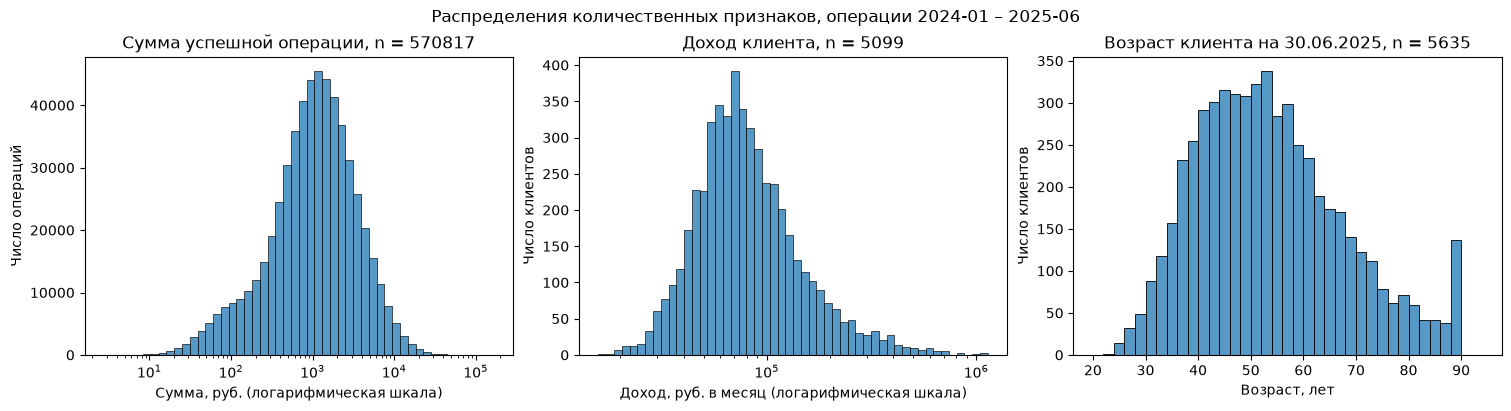

In [62]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")

sns.histplot(amount_rub, bins=50, log_scale=True, ax=axes[0])
axes[0].set_title(f"Сумма успешной операции, n = {len(amount_rub)}")
axes[0].set_xlabel("Сумма, руб. (логарифмическая шкала)")
axes[0].set_ylabel("Число операций")

income_known = clients["monthly_income"].dropna()
sns.histplot(income_known, bins=50, log_scale=True, ax=axes[1])
axes[1].set_title(f"Доход клиента, n = {len(income_known)}")
axes[1].set_xlabel("Доход, руб. в месяц (логарифмическая шкала)")
axes[1].set_ylabel("Число клиентов")

sns.histplot(clients["age"], bins=range(20, 95, 2), ax=axes[2])
axes[2].set_title(f"Возраст клиента на 30.06.2025, n = {len(clients)}")
axes[2].set_xlabel("Возраст, лет")
axes[2].set_ylabel("Число клиентов")

fig.suptitle("Распределения количественных признаков, операции 2024-01 – 2025-06")
plt.show()

На логарифмической шкале суммы операций и доходы выглядят как один симметричный горб, то есть на обычной шкале у них длинный правый хвост. Основная масса операций – от сотни до десяти тысяч рублей. Доход тянется до миллиона рублей в месяц за счет клиентов `Private`.
У возраста широкий горб от 35 до 60 лет, но в самом конце, на 88 годах, виден резкий столбик. Проверяем, сколько там клиентов.

In [63]:
clients["age"].value_counts().sort_index().tail(8)

age
81     23
82     21
83     21
84     21
85     20
86     17
87     21
88    137
Name: count, dtype: int64

В каждом возрасте от 81 до 87 лет по 17–23 клиента, а в 88 лет сразу 137. Похоже, возраст при выгрузке ограничили сверху, и всех клиентов старше записали как 88 летних(цензурированием сверху). Настоящий возраст этих клиентов неизвестен, и восстановить его по данным нельзя. Но они все равно попадают в старшую возрастную группу, поэтому для разрезов по возрасту это почти не важно. Отмечаем это как ограничение данных.

`satisfaction_score` – порядковая шкала, поэтому для нее не считаем среднее, а смотрим частоты и медиану. Считаем только по клиентам, у которых оценка есть.

In [64]:
score = clients["satisfaction_score"].dropna().astype(int)
score_freq = score.value_counts().sort_index().to_frame("клиентов")
score_freq["доля, %"] = (score_freq["клиентов"] / len(score) * 100).round(1)
print("клиентов с оценкой:", len(score), "из", len(clients), "| медиана:", score.median())
score_freq

клиентов с оценкой: 2309 из 5635 | медиана: 3.0


,клиентов,"доля, %"
satisfaction_score,,
1,294,12.7
2,461,20.0
3,444,19.2
4,469,20.3
5,641,27.8


Оценка есть у 2309 клиентов из 5635, медиана равна 3. Чаще всего ставят 5, реже всего 1, остальные оценки примерно поровну. Среднее по этой шкале не считаем, так как расстояния между оценками не определены.

### 5.2. Частотные характеристики категориальных признаков

Смотрим, сколько клиентов в каждой категории. Доля считается от всех клиентов справочника, для `income_source` пропуски показаны отдельной строкой.

In [65]:
cat_cols = ["segment", "loyalty_tier", "card_type", "city", "gender", "has_mobile_app", "marketing_opt_in", "income_source"]
cat_freq = pd.concat({col: clients[col].value_counts(dropna=False, sort=col != "loyalty_tier") for col in cat_cols}).to_frame("клиентов")
cat_freq["доля, %"] = (cat_freq["клиентов"] / len(clients) * 100).round(1)
print("клиентов:", len(clients))
cat_freq

клиентов: 5635


клиентов  доля, %
segment          Массовый                     2889     51.3
                 Зарплатный                   1568     27.8
                 Премиальный                   956     17.0
                 Private                       222      3.9
loyalty_tier     Базовый                      2831     50.2
                 Серебро                      1492     26.5
                 Золото                       1002     17.8
                 Платина                       310      5.5
card_type        Дебетовая                    3887     69.0
                 Кредитная                    1210     21.5
                 Премиальная                   538      9.5
city             Москва                       1646     29.2
                 Санкт-Петербург              1004     17.8
                 Новосибирск                   895     15.9
                 Екатеринбург                  709     12.6
                 Нижний Новгород               691     12.3
                 Казань                        690     12.2
gender           Ж                            2832     50.3
                 М                            2803     49.7
has_mobile_app   True                         3488     61.9
                 False                        2147     38.1
marketing_opt_in True                         4977     88.3
                 False                         658     11.7
income_source    Зарплата в нашем банке       2520     44.7
                 Зарплата в другом банке      1587     28.2
                 NaN                          1528     27.1

Из 5635 клиентов справочника половина – массовый сегмент (51.3%) и базовый уровень лояльности (50.2%), Private всего 3.9%. У 69.0% дебетовая карта. Больше всего клиентов в Москве (29.2%), мужчин и женщин примерно поровну. Приложение есть у 61.9% клиентов. Согласие на маркетинговую коммуникацию дали 88.3%, то есть 658 клиентов кампанией охватить нельзя. Источник дохода неизвестен у 27.1%.

Частоты категорий трат и каналов по успешным операциям периода. Для категорий добавляем накопленную долю, как в диаграмме Парето так будет видно, какие категории дают основную часть операций.

In [66]:
cat_ops = txn_ok["category"].value_counts().to_frame("операций")
cat_ops["доля, %"] = (cat_ops["операций"] / len(txn_ok) * 100).round(1)
cat_ops["накопленная доля, %"] = (cat_ops["операций"].cumsum() / len(txn_ok) * 100).round(1)

ch_ops = txn_ok["channel"].value_counts().to_frame("операций")
ch_ops["доля, %"] = (ch_ops["операций"] / len(txn_ok) * 100).round(1)

print("успешных операций:", len(txn_ok))
display(cat_ops)
display(ch_ops)

успешных операций: 573137


,операций,"доля, %","накопленная доля, %"
category,,,
Продукты,151228,26.4,26.4
Кафе и рестораны,78361,13.7,40.1
Транспорт,60737,10.6,50.7
Одежда и обувь,58780,10.3,60.9
АЗС,53082,9.3,70.2
Связь и интернет,44995,7.9,78.0
Развлечения и досуг,43709,7.6,85.7
Аптеки,41660,7.3,92.9
Онлайн-сервисы,40585,7.1,100.0


,операций,"доля, %"
channel,,
Карта,294548,51.4
СБП,98183,17.1
Токен,93698,16.3
Онлайн-банк,86708,15.1


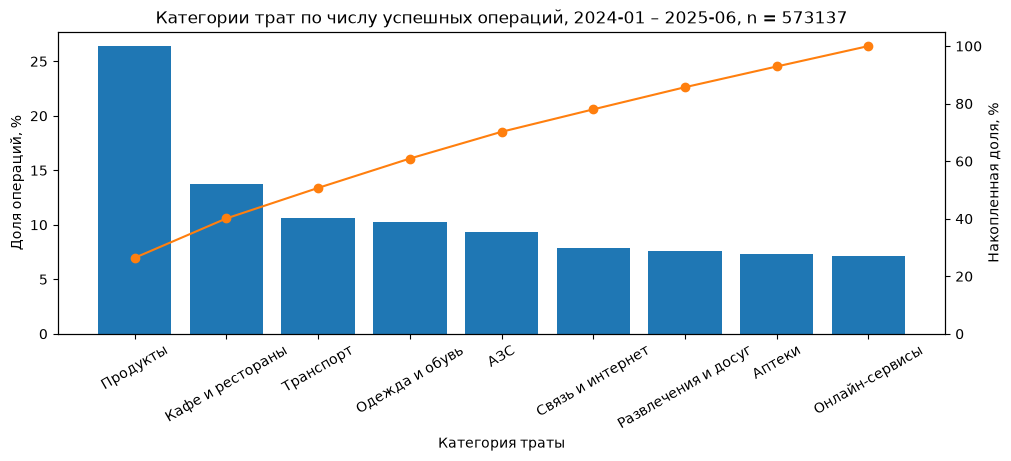

In [67]:
fig, ax = plt.subplots(figsize=(10, 4.5), layout="constrained")
ax.bar(cat_ops.index, cat_ops["доля, %"])
ax.set_ylabel("Доля операций, %")
ax.set_xlabel("Категория траты")
ax.tick_params(axis="x", rotation=30)
ax2 = ax.twinx()
ax2.plot(cat_ops.index, cat_ops["накопленная доля, %"], color="C1", marker="o")
ax2.set_ylim(0, 105)
ax2.set_ylabel("Накопленная доля, %")
ax.set_title(f"Категории трат по числу успешных операций, 2024-01 – 2025-06, n = {len(txn_ok)}")
plt.show()

Больше всего операций приходится на продукты, это 26.4% из 573137 успешных операций. Четыре первые категории вместе дают 60.9% операций, а на каждую из остальных пяти приходится по 7–9%. Явного длинного хвоста нет, все девять категорий заметны.
По каналам половина операций оплачена пластиковой картой (51.4%). Остальное почти поровну делят `СБП` (17.1%), `Токен` (16.3%) и `Онлайн-банк` (15.1%).

### 5.3. Динамика по месяцам

Динамику по месяцам считаем по успешным операциям клиентов из справочника. Месяцы разной длины, поэтому кроме числа операций смотрим еще число операций в день. Активным в месяце считаем клиента, у которого за этот месяц была хотя бы одна успешная трата.

In [68]:
txn_ok = txn_ok.assign(month=txn_ok["txn_datetime"].dt.to_period("M"))
monthly = txn_ok.groupby("month").agg(ops=("txn_id", "size"), active=("client_id", "nunique"))
monthly["ops_per_day"] = (monthly["ops"] / monthly.index.days_in_month).round(0)
monthly["ops_per_active"] = (monthly["ops"] / monthly["active"]).round(2)
monthly.rename(columns={"ops": "операций", "active": "активных клиентов",
                        "ops_per_day": "операций в день", "ops_per_active": "операций на активного клиента"})

,операций,активных клиентов,операций в день,операций на активного клиента
month,,,,
2024-01,24203,4623,781.0,5.24
2024-02,30099,4696,1038.0,6.41
2024-03,34178,4748,1103.0,7.20
2024-04,33826,4724,1128.0,7.16
2024-05,30969,4721,999.0,6.56
2024-06,33802,4729,1127.0,7.15
2024-07,34697,4769,1119.0,7.28
2024-08,35890,4840,1158.0,7.42
2024-09,34404,4906,1147.0,7.01


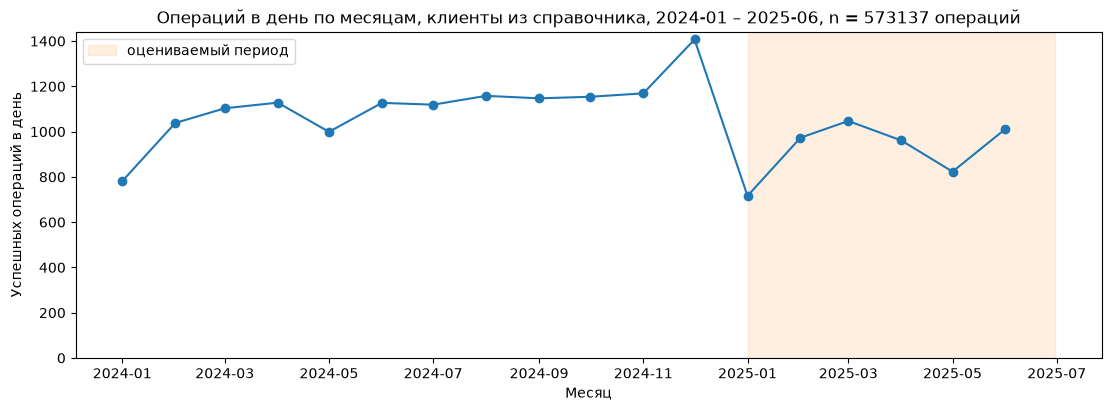

In [69]:
fig, ax = plt.subplots(figsize=(11, 4), layout="constrained")
x = monthly.index.to_timestamp()
ax.plot(x, monthly["ops_per_day"], marker="o")
ax.axvspan(pd.Timestamp("2025-01-01"), pd.Timestamp("2025-06-30"), color="C1", alpha=0.12, label="оцениваемый период")
ax.set_ylim(0, None)
ax.set_xlabel("Месяц")
ax.set_ylabel("Успешных операций в день")
ax.set_title(f"Операций в день по месяцам, клиенты из справочника, 2024-01 – 2025-06, n = {len(txn_ok)} операций")
ax.legend()
plt.show()

Весь 2024 год, кроме января, активность держится от 999 до 1169 операций в день. В декабре всплеск до 1407, это предновогодние покупки. В январе 2025 года провал до 716 операций в день, это ниже, чем в январе 2024 года (781). Дальше 2025 год идет ниже прошлого года в те же месяцы. В марте 1047 против 1103, в мае 823 против 999. Январь был низким и в 2024 году, так что часть январского провала объясняется сезонностью. Но в 2025 году ниже весь уровень активности.

Окна разной длины, и в базовый год попадают и декабрьский всплеск, и январский провал. Поэтому сравниваем среднее за месяц в трех окнах: весь 2024 год (базовое окно из задания), январь – июнь 2024 (те же месяцы, что в оцениваемом окне) и январь – июнь 2025.

In [70]:
windows = {"2024, 12 мес.": ("2024-01", "2024-12"),
           "янв – июн 2024": ("2024-01", "2024-06"),
           "янв – июн 2025": ("2025-01", "2025-06")}
win = pd.DataFrame({name: monthly.loc[a:b, ["ops", "ops_per_day", "ops_per_active"]].mean() for name, (a, b) in windows.items()}).T
win.columns = ["операций в месяц", "операций в день", "операций на активного клиента"]
win.round(2)

,операций в месяц,операций в день,операций на активного клиента
"2024, 12 мес.",33878.00,1110.83,7.01
янв – июн 2024,31179.50,1029.33,6.62
янв – июн 2025,27766.83,922.00,5.59


Если сравнивать с целым 2024 годом, в 2025 году было 922 операции в день против 1110.83. Если сравнивать с теми же месяцами 2024 года, то 922 против 1029.33. Разница между этими двумя сравнениями объясняется сезонностью. За целый год среднее выше из-за декабрьского всплеска, а январь, февраль и остальные месяцы первого полугодия и в 2024 году были ниже среднего за год. Операций на одного активного клиента стало 5.59 против 6.62 в первом полугодии 2024 года. Базовое окно задано в задании, это весь 2024 год. Поэтому падение по метрике будет включать и сезонную часть, и это нужно помнить при чтении результатов.

Смотрим, как менялись доли каналов по месяцам. Доля считается от всех успешных операций месяца.

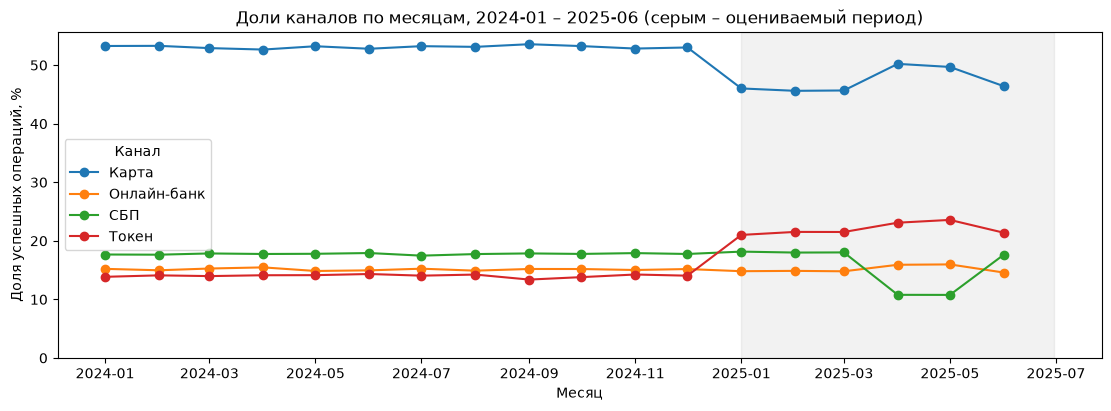

channel,Карта,Онлайн-банк,СБП,Токен
month,,,,
2024-10,53.3,15.2,17.8,13.8
2024-11,52.8,15.0,17.9,14.2
2024-12,53.0,15.2,17.8,14.0
2025-01,46.0,14.8,18.2,21.0
2025-02,45.6,14.9,18.0,21.5
2025-03,45.7,14.8,18.0,21.5
2025-04,50.2,15.9,10.8,23.1
2025-05,49.7,16.0,10.8,23.6
2025-06,46.4,14.6,17.6,21.4


In [71]:
channel_share = pd.crosstab(txn_ok["month"], txn_ok["channel"], normalize="index") * 100
fig, ax = plt.subplots(figsize=(11, 4), layout="constrained")
for ch in channel_share.columns:
    ax.plot(channel_share.index.to_timestamp(), channel_share[ch], marker="o", label=ch)
ax.axvspan(pd.Timestamp("2025-01-01"), pd.Timestamp("2025-06-30"), color="grey", alpha=0.1)
ax.set_ylim(0, None)
ax.set_xlabel("Месяц")
ax.set_ylabel("Доля успешных операций, %")
ax.set_title("Доли каналов по месяцам, 2024-01 – 2025-06 (серым – оцениваемый период)")
ax.legend(title="Канал")
plt.show()
channel_share.round(1).loc["2024-10":]

До конца 2024 года доли каналов были стабильны карта около 53%, СБП около 18%, онлайн-банк около 15%, токен около 14%. С января 2025 года доля токена выросла до 21–24%, а доля пластиковой карты упала до 46–50%, так как часть клиентов стала платить телефоном вместо карты. Это не потеря активности, а смена способа оплаты. Еще одна особенность заметна у СБП. В апреле и мае 2025 года его доля упала до 10.8%, а в июне вернулась к 17.6%. Похоже на временный сбой или ограничение СБП в эти два месяца.

Смотрим, как менялась каждая категория. Категории сильно отличаются по размеру, поэтому сравниваем не сами числа, а индекс. Для каждой категории делим число операций в день за месяц на ее среднее за 2024 год и умножаем на 100. Значение 100 означает обычный для категории уровень базового года, меньше 100 – спад, больше 100 – рост.

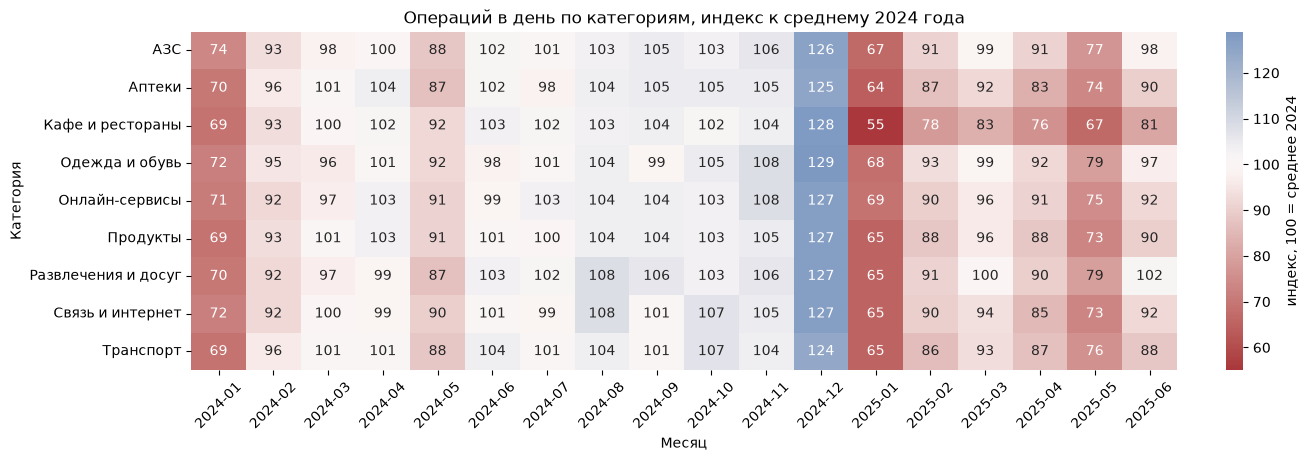

category
Кафе и рестораны       73.0
Аптеки                 82.0
Продукты               83.0
Связь и интернет       83.0
Транспорт              83.0
Онлайн-сервисы         85.0
АЗС                    87.0
Одежда и обувь         88.0
Развлечения и досуг    88.0
dtype: float64

In [72]:
cat_month = txn_ok.groupby(["category", "month"]).size().unstack()
cat_per_day = cat_month / cat_month.columns.days_in_month
cat_index = cat_per_day.div(cat_per_day.loc[:, "2024-01":"2024-12"].mean(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(13, 4.5), layout="constrained")
sns.heatmap(cat_index.round(0), annot=True, fmt=".0f", cmap="vlag_r", center=100, cbar_kws={"label": "индекс, 100 = среднее 2024"}, ax=ax)
ax.set_xlabel("Месяц")
ax.set_ylabel("Категория")
ax.set_title("Операций в день по категориям, индекс к среднему 2024 года")
ax.tick_params(axis="x", rotation=45)
plt.show()
cat_index.loc[:, "2025-01":"2025-06"].mean(axis=1).round(0).sort_values()

В 2025 году просели все категории, но `Кафе и рестораны` просел сильнее остальных. В среднем за первое полугодие 2025 года индекс у кафе и ресторанов 73, а у остальных категорий от 82 до 88. Январь был низким у всех категорий и в 2024 году, индекс тогда был около 70. Значит январский провал объясняется общей сезонностью, а не особенностью отдельной категории.

### 5.4. Разрезы и связи между признаками

Рассмотрим разрезы. Для каждой группы клиентов считаем, сколько успешных операций в среднем приходится на одного клиента в месяц. Считаем это отдельно для базового окна, это 12 месяцев 2024 года, и для оцениваемого, это первые 6 месяцев 2025 года. Окна разной длины, поэтому число операций делим на число месяцев в окне. Изменение в процентах показывает, насколько оцениваемое окно ниже базового.

In [73]:
clients["age_group"] = pd.cut(clients["age"], [0, 35, 55, 120], labels=["до 35", "35–54", "55+"], right=False)
txn_ok = txn_ok.assign(period=np.where(txn_ok["month"] <= pd.Period("2024-12"), "base", "eval"))
txn_ok = txn_ok.merge(clients[["client_id", "segment", "loyalty_tier", "card_type", "city", "has_mobile_app", "age_group"]],
                      on="client_id", how="left")


def activity_by(cols, ops=txn_ok, people=clients):
    """Операций на клиента в месяц в базовом и оцениваемом окне по группам."""
    counts = ops.groupby(cols + ["period"], observed=True).size().unstack()
    n = people.groupby(cols, observed=True).size()
    res = pd.DataFrame({"клиентов": n,
                        "база, оп./мес.": counts["base"] / n / 12,
                        "оценка, оп./мес.": counts["eval"] / n / 6})
    res["изменение, %"] = (res["оценка, оп./мес."] / res["база, оп./мес."] - 1) * 100
    return res.round(2)


cuts = pd.concat({col: activity_by([col]) for col in
                  ["segment", "has_mobile_app", "age_group", "loyalty_tier", "card_type", "city"]})
total = pd.DataFrame({"база": [len(txn_ok[txn_ok["period"] == "base"]) / len(clients) / 12],
                      "оценка": [len(txn_ok[txn_ok["period"] == "eval"]) / len(clients) / 6]})
total["изменение, %"] = (total["оценка"] / total["база"] - 1) * 100
print("в среднем по всем клиентам:", total.round(2).to_dict("records")[0])
cuts

в среднем по всем клиентам: {'база': 6.01, 'оценка': 4.93, 'изменение, %': -18.04}


клиентов  база, оп./мес.  оценка, оп./мес.  изменение, %
segment        Private               222            7.10              6.13        -13.75
               Зарплатный           1568            6.61              6.23         -5.82
               Массовый             2889            5.29              3.60        -31.99
               Премиальный           956            6.94              6.53         -6.00
has_mobile_app False                2147            5.84              4.43        -24.20
               True                 3488            6.12              5.23        -14.41
age_group      до 35                 369            7.21              6.29        -12.71
               35–54                2896            6.44              5.45        -15.40
               55+                  2370            5.30              4.08        -23.08
loyalty_tier   Базовый              2831            5.70              4.40        -22.76
               Серебро              1492            6.17              5.11        -17.09
               Золото               1002            6.47              5.77        -10.83
               Платина               310            6.69              6.15         -8.04
card_type      Дебетовая            3887            5.81              4.63        -20.33
               Кредитная            1210            6.20              5.19        -16.28
               Премиальная           538            7.04              6.49         -7.83
city           Екатеринбург          709            6.06              5.08        -16.18
               Казань                690            6.02              5.13        -14.80
               Москва               1646            6.12              5.02        -17.93
               Нижний Новгород       691            6.19              5.26        -14.89
               Новосибирск           895            5.54              3.94        -28.77
               Санкт-Петербург      1004            6.10              5.17        -15.24

В среднем по всем клиентам операций на одного клиента в месяц стало меньше на 18.04%, было 6.01, стало 4.93. Сильнее всего упал массовый сегмент, на 31.99%. У зарплатного и премиального сегментов падение всего 5.82% и 6.00%. Сильнее среднего падают клиенты без приложения (-24.20% против -14.41% у клиентов с приложением), клиенты 55+ (-23.08%), клиенты базового уровня лояльности (-22.76%) и владельцы дебетовой карты (-20.33%). Из городов выделяется Новосибирск с падением 28.77%, у остальных городов от 14.80% до 17.93%. Разрезы пересекаются, ведь один клиент может быть и массовым, и без приложения, и старше 55. Поэтому дальше проверяем, что из этого действительно связано с падением.

Проверяем, нет ли здесь парадокса Симпсона. Новосибирск падает заметно сильнее других городов, поэтому смотрим, из каких клиентов он состоит и как падает массовый сегмент в каждом городе.

In [74]:
mass_share = (pd.crosstab(clients["city"], clients["segment"], normalize="index")["Массовый"] * 100).round(1)
mass_by_city = activity_by(["city"], ops=txn_ok[txn_ok["segment"] == "Массовый"],
                           people=clients[clients["segment"] == "Массовый"])
mass_by_city.insert(0, "доля массового сегмента в городе, %", mass_share)
mass_by_city

,"доля массового сегмента в городе, %",клиентов,"база, оп./мес.","оценка, оп./мес.","изменение, %"
city,,,,,
Екатеринбург,47.0,333,5.10,3.47,-32.05
Казань,41.6,287,5.36,3.88,-27.55
Москва,45.6,750,5.47,3.62,-33.78
Нижний Новгород,44.9,310,4.97,3.41,-31.38
Новосибирск,87.0,779,5.30,3.63,-31.56
Санкт-Петербург,42.8,430,5.31,3.56,-32.91


В Новосибирске массовых клиентов 87.0%, а в других городах от 41.6% до 47.0%. При этом внутри массового сегмента Новосибирск падает так же, как другие города, на 31.56% при разбросе у остальных от 27.55% до 33.78%. Значит сильное падение Новосибирска объясняется не самим городом, а тем, что там почти все клиенты массовые. Это и есть парадокс Симпсона, когда результат по городу на самом деле отражает состав его клиентов. Поэтому город в правила групп не берем.

Теперь внутри каждого сегмента смотрим, как падение связано с наличием приложения и с возрастом.

In [75]:
seg_app = activity_by(["segment", "has_mobile_app"])["изменение, %"].unstack()
seg_age = activity_by(["segment", "age_group"])["изменение, %"].unstack()
display(seg_app.rename(columns={True: "с приложением", False: "без приложения"}))
seg_age

has_mobile_app,без приложения,с приложением
segment,,
Private,-18.60,-11.09
Зарплатный,-9.81,-3.54
Массовый,-41.90,-26.20
Премиальный,-7.73,-4.90


age_group,до 35,35–54,55+
segment,,,
Private,-10.11,-9.16,-22.04
Зарплатный,-3.76,-2.86,-10.49
Массовый,-23.46,-29.87,-36.86
Премиальный,-3.30,-3.45,-10.69


В каждом сегменте клиенты без приложения теряют активность сильнее, чем клиенты с приложением. Сильнее всего падают массовые клиенты без приложения, на 41.90%, а массовые с приложением на 26.20%. С возрастом картина такая же. В каждом сегменте клиенты 55+ падают сильнее остальных, в массовом сегменте на 36.86%. При этом массовый сегмент падает сильно в любой группе. Даже массовые клиенты до 35 лет теряют 23.46%, это больше, чем у любой группы других сегментов.

Смотрим, как изменились доли каналов у клиентов с приложением и без него. Доля считается от успешных операций группы в каждом окне.

In [76]:
(pd.crosstab([txn_ok["has_mobile_app"], txn_ok["period"]], txn_ok["channel"], normalize="index") * 100).round(1)

channel                Карта  Онлайн-банк   СБП  Токен
has_mobile_app period                                 
False          base     56.2         17.1  16.8    9.8
               eval     57.9         17.4  14.6   10.1
True           base     51.2         14.0  18.3   16.5
               eval     41.7         14.0  16.1   28.2

У клиентов с приложением доля токена выросла с 16.5% до 28.2%, а доля карты упала с 51.2% до 41.7%. То есть они перешли с пластика на оплату телефоном. У клиентов без приложения каналы почти не изменились, доля токена была 9.8% и стала 10.1%. Поэтому если считать активность только по пластиковой карте, у клиентов с приложением получится ложное падение.

Категория `Кафе и рестораны` упала сильнее остальных. Смотрим, в каких сегментах.

In [77]:
activity_by(["segment"], ops=txn_ok[txn_ok["category"] == "Кафе и рестораны"])

,клиентов,"база, оп./мес.","оценка, оп./мес.","изменение, %"
segment,,,,
Private,222,1.58,1.16,-26.87
Зарплатный,1568,0.92,0.78,-15.53
Массовый,2889,0.59,0.35,-41.09
Премиальный,956,1.37,1.04,-24.10


Траты в кафе и ресторанах упали во всех сегментах, но у массового сильнее всего, на 41.09%. У зарплатного сегмента падение 15.53%, у премиального 24.10%, у Private 26.87%.

Теперь смотрим связи между числовыми признаками клиента. Для каждого клиента считаем число операций в месяц в обоих окнах и их разницу. Потом строим матрицу корреляций Спирмена.

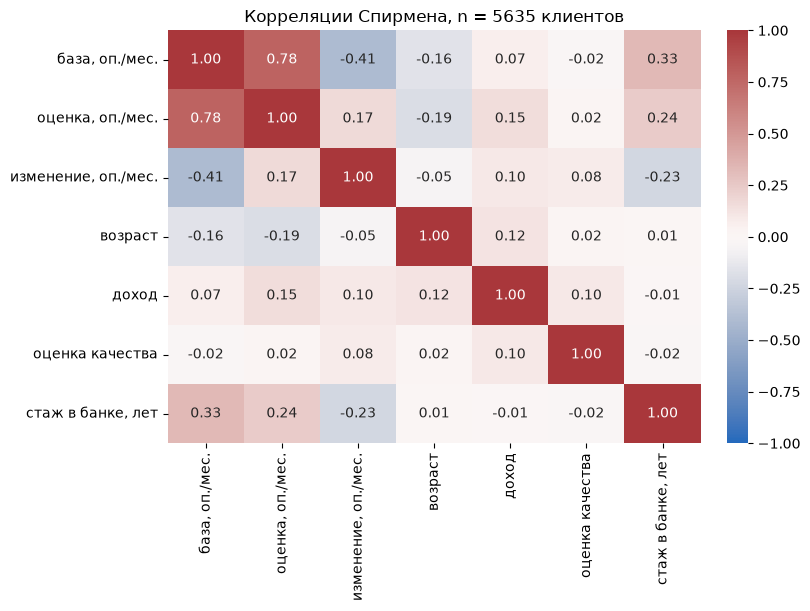

In [78]:
per_client = (txn_ok.groupby(["client_id", "period"]).size().unstack(fill_value=0)
              .reindex(clients["client_id"], fill_value=0))
per_client = pd.DataFrame({"база, оп./мес.": per_client["base"] / 12, "оценка, оп./мес.": per_client["eval"] / 6})
per_client["изменение, оп./мес."] = per_client["оценка, оп./мес."] - per_client["база, оп./мес."]
features = clients.set_index("client_id")[["age", "monthly_income", "satisfaction_score"]]
features["стаж в банке, лет"] = (pd.Timestamp("2025-06-30") - clients.set_index("client_id")["registration_date"]).dt.days / 365.25
corr = per_client.join(features).rename(columns={"age": "возраст", "monthly_income": "доход", "satisfaction_score": "оценка качества"}).corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6), layout="constrained")
sns.heatmap(corr.round(2), annot=True, fmt=".2f", vmin=-1, vmax=1, center=0, cmap="vlag", ax=ax)
ax.set_title(f"Корреляции Спирмена, n = {len(per_client)} клиентов")
plt.show()

Изменение активности сильнее всего связано с уровнем в базовом окне, корреляция -0.41. Кто раньше был активнее, тот в абсолютных числах и потерял больше. Со стажем в банке связь слабая отрицательная, -0.23. Возможно, здесь влияют новые клиенты, ведь у пришедших в 2024 году базовое окно неполное, а мы все равно делим на 12 месяцев. Это учтем в метрике. С возрастом, доходом и оценкой качества изменение почти не связано, корреляции от -0.05 до 0.10. Доход и оценка известны не у всех клиентов, поэтому для них корреляция считается только по тем, у кого значение есть.

## 6. Метрика активности

Что именно вы считаете активностью, как она вычисляется, на каком
множестве клиентов, за какие окна. Отдельно: какое снижение эта метрика
**не увидит**.

Активностью считаем число успешных оплат картой в месяц. Оплатой картой считаем операции с каналом `Карта` и `Токен`. Токен – это та же карта, только в телефоне, а в 5.4 видно, что клиенты с приложением в 2025 году перешли с пластика на токен. Если считать только `Карта`, этот переход выглядел бы как падение. `СБП` и `Онлайн-банк` не считаем. По описанию это перевод и операция в интернет-банке, но проверим, что это за операции на самом деле. Сравниваем, на какие категории приходятся операции каждого канала и какая у них медианная сумма. Доля считается от успешных операций канала, сумма только по рублевым операциям.

In [79]:
channel_cat = (pd.crosstab(txn_ok["category"], txn_ok["channel"], normalize="columns") * 100).round(1)
channel_cat.loc["медианная сумма, руб."] = txn_ok[txn_ok["currency"] == "RUB"].groupby("channel")["amount"].median().round(0)
channel_cat

channel,Карта,Онлайн-банк,СБП,Токен
category,,,,
АЗС,9.3,9.3,9.2,9.2
Аптеки,7.3,7.3,7.3,7.2
Кафе и рестораны,13.7,13.6,13.8,13.6
Одежда и обувь,10.3,10.2,10.4,10.2
Онлайн-сервисы,7.1,7.1,7.1,7.2
Продукты,26.4,26.5,26.3,26.4
Развлечения и досуг,7.5,7.6,7.8,7.7
Связь и интернет,7.9,7.8,7.9,7.8
Транспорт,10.7,10.7,10.3,10.6


Во всех четырех каналах доли категорий почти одинаковые, разница не больше 0.4 процентного пункта, а медианная сумма от 1064 до 1085 рублей. Значит, через `СБП` и `Онлайн-банк` клиенты платят за те же покупки, что и картой, это не переводы. Но по описанию каналов оплатой картой являются только `Карта` и `Токен`, а заказчик говорит о том, что клиенты стали реже пользоваться именно картами. Поэтому в метрику их не включаем. К тому же у `СБП` был провал в апреле и мае 2025 года (5.3), который к картам не относится. Как изменится результат, если считать все каналы, проверим ниже.

Считаем число операций, а не сумму. Сумма сильно зависит от редких крупных покупок (3.4) и от валюты, а курсов EUR и USD в данных нет.

Окна заданы условием. Базовое окно – 2024 год, оцениваемое – январь–июнь 2025 года. Окна разной длины, поэтому оба переводим в операции в месяц. Операции оценочного окна делим на 6 месяцев. С базой сложнее. Ни у одного клиента первая операция не раньше даты открытия карты `card_open_date`, а у части клиентов карта открыта только во второй половине 2024 года. Если делить их операции на 12 месяцев, база будет занижена. Поэтому операции базового окна делим на число месяцев 2024 года, когда карта уже была открыта.

Метрику считаем на клиентах из справочника. Не берем клиентов с картой, открытой в 2025 году, у них нет базы. Не берем карты, открытые в октябре–декабре 2024 года. База у них меньше трех месяцев, и в нее попадает декабрьский всплеск (5.3), поэтому она ненадежна. Также убираем клиентов без единой оплаты картой в базовом окне, для них изменение в процентах не считается.

In [80]:
pay = txn_ok[txn_ok["channel"].isin(["Карта", "Токен"])]
counts = (pay.groupby(["client_id", "period"]).size().unstack(fill_value=0)
          .reindex(clients["client_id"], fill_value=0))

card_open = clients.set_index("client_id")["card_open_date"]
base_start = card_open.clip(lower=pd.Timestamp("2024-01-01"))
base_months = (12 * (pd.Timestamp("2025-01-01") - base_start).dt.days / 366).clip(lower=0)

metric = pd.DataFrame({"месяцев в базе": base_months,
                       "база, оп./мес.": counts["base"] / base_months,
                       "оценка, оп./мес.": counts["eval"] / 6})

funnel = pd.Series({
    "клиентов в справочнике": len(metric),
    "карта открыта в 2025 году": (card_open >= "2025-01-01").sum(),
    "карта открыта в октябре–декабре 2024 года": ((card_open >= "2024-10-01") & (card_open < "2025-01-01")).sum(),
})
metric = metric[metric["месяцев в базе"] >= 3]
funnel["нет оплат картой в базовом окне"] = (metric["база, оп./мес."] == 0).sum()
metric = metric[metric["база, оп./мес."] > 0]
funnel["остается для метрики"] = len(metric)
metric["изменение, %"] = (metric["оценка, оп./мес."] / metric["база, оп./мес."] - 1) * 100
funnel.to_frame("клиентов")

,клиентов
клиентов в справочнике,5635
карта открыта в 2025 году,321
карта открыта в октябре–декабре 2024 года,252
нет оплат картой в базовом окне,18
остается для метрики,5044


Из 5635 клиентов метрику можно посчитать для 5044. Для остальных нет базы, с которой можно сравнить, поэтому про них нельзя сказать, упала ли активность. В кампанию их не включаем, подробнее в 7.1.

Смотрим, как изменилась метрика у отдельных клиентов. Изменение у клиента может быть очень большим, если база маленькая (например, одна покупка в базе и шесть в оценке), поэтому для изменения смотрим медиану и квартили, а не среднее. Доля в таблице считается от 5044 клиентов метрики.

In [81]:
metric_stats = metric[["база, оп./мес.", "оценка, оп./мес.", "изменение, %"]].describe().round(2)
display(metric_stats)
change_bins = pd.cut(metric["изменение, %"], [-np.inf, -90, -50, -20, 0, np.inf], right=False,
                     labels=["упала больше чем на 90%", "упала на 50–90%", "упала на 20–50%",
                             "упала меньше чем на 20%", "не упала"])
bins_table = change_bins.value_counts(sort=False).to_frame("клиентов")
bins_table["доля, %"] = (bins_table["клиентов"] / len(metric) * 100).round(1)
print("оплат картой в оценке нет совсем:", (metric["оценка, оп./мес."] == 0).sum())
deep = metric["изменение, %"] < -50
is_mass = clients.set_index("client_id").loc[metric.index, "segment"] == "Массовый"
print("доля массового сегмента среди клиентов с падением больше 50%, %:", round(is_mass[deep].mean() * 100, 1))
print("доля массового сегмента среди остальных клиентов, %:", round(is_mass[~deep].mean() * 100, 1))
bins_table

,"база, оп./мес.","оценка, оп./мес.","изменение, %"
count,5044.00,5044.00,5044.00
mean,4.54,3.70,-17.58
std,3.10,3.32,47.17
min,0.08,0.00,-100.00
25%,2.42,1.33,-52.94
50%,3.92,2.83,-20.00
75%,6.00,5.00,7.14
max,27.50,34.83,500.00


оплат картой в оценке нет совсем: 65
доля массового сегмента среди клиентов с падением больше 50%, %: 77.4
доля массового сегмента среди остальных клиентов, %: 43.6


,клиентов,"доля, %"
"изменение, %",,
упала больше чем на 90%,85,1.7
упала на 50–90%,1240,24.6
упала на 20–50%,1214,24.1
упала меньше чем на 20%,925,18.3
не упала,1580,31.3


В базе у клиента в медиане 3.92 оплаты картой в месяц, в оценке 2.83. Медиана изменения -20.0%, у четверти клиентов падение больше 52.94%. Не упала активность у 1580 клиентов (31.3%), у 85 клиентов (1.7%) упала больше чем на 90%, у 65 из них оплат картой в 2025 году нет совсем. Среди клиентов с падением больше 50% массовых 77.4%, а среди остальных клиентов 43.6%.

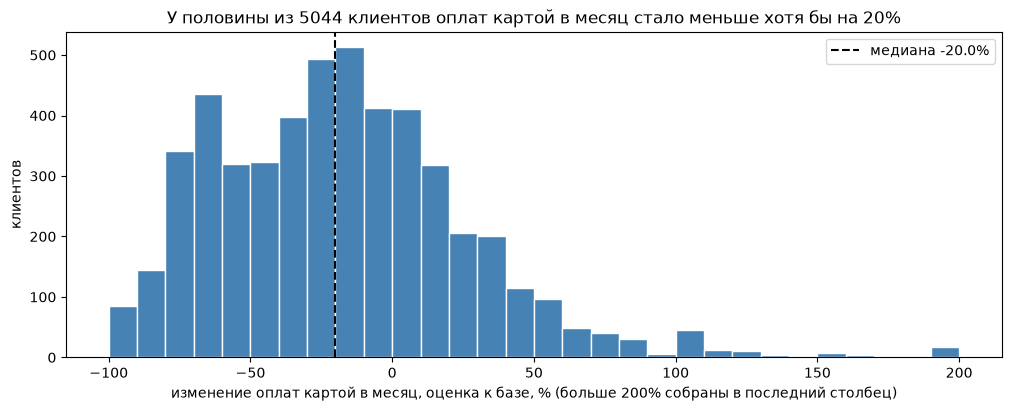

In [82]:
fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
ax.hist(metric["изменение, %"].clip(upper=200), bins=np.arange(-100, 210, 10), color="steelblue", edgecolor="white")
ax.axvline(metric["изменение, %"].median(), color="black", linestyle="--",
           label=f"медиана {metric['изменение, %'].median():.1f}%")
ax.set_xlabel("изменение оплат картой в месяц, оценка к базе, % (больше 200% собраны в последний столбец)")
ax.set_ylabel("клиентов")
ax.set_title(f"У половины из {len(metric)} клиентов оплат картой в месяц стало меньше хотя бы на {abs(metric['изменение, %'].median()):.0f}%")
ax.legend()
plt.show()

У распределения два горба. Первый около -15%, это клиенты, у которых активность изменилась мало. Второй около -65%, это клиенты, которые стали платить картой в разы реже. Значит, падение – это не небольшое снижение у всех, а сильное падение у части клиентов, и в основном это массовый сегмент.

Проверяем, насколько вывод зависит от выбора метрики. Считаем изменение для всех клиентов и по сегментам в нескольких вариантах на тех же клиентах. Изменение группы считаем по сумме метрики всех ее клиентов, как в 5.4. Для варианта с базой январь–июнь 2024 берем только клиентов, у которых карта открыта до 2024 года, чтобы сравнивать одни и те же месяцы.

In [83]:
same_months = pay[(pay["month"] <= pd.Period("2024-06")) | (pay["period"] == "eval")]
variants = {
    "Карта и Токен, число операций (выбранная)": (pay, metric["месяцев в базе"], "txn_id"),
    "все каналы, число операций": (txn_ok, metric["месяцев в базе"], "txn_id"),
    "только Карта, число операций": (pay[pay["channel"] == "Карта"], metric["месяцев в базе"], "txn_id"),
    "Карта и Токен, сумма в рублях": (pay[pay["currency"] == "RUB"], metric["месяцев в базе"], "amount"),
    "Карта и Токен, база только январь–июнь 2024": (same_months, metric["месяцев в базе"].where(card_open < "2024-01-01").dropna() / 2, "txn_id"),
}

robust = {}
for name, (ops, months, col) in variants.items():
    agg = "count" if col == "txn_id" else "sum"
    s = (ops.groupby(["client_id", "period"])[col].agg(agg).unstack(fill_value=0)
         .reindex(months.index, fill_value=0))
    per = pd.DataFrame({"base": s["base"] / months, "eval": s["eval"] / 6})
    per = per.join(clients.set_index("client_id")["segment"])
    by_seg = per.groupby("segment")[["base", "eval"]].sum()
    row = (by_seg["eval"] / by_seg["base"] - 1) * 100
    row["все клиенты"] = (per["eval"].sum() / per["base"].sum() - 1) * 100
    row["клиентов"] = len(per)
    robust[name] = row
robust = pd.DataFrame(robust).T[["клиентов", "все клиенты", "Массовый", "Зарплатный", "Премиальный", "Private"]]
robust["клиентов"] = robust["клиентов"].astype(int)
robust.round(2)

segment,клиентов,все клиенты,Массовый,Зарплатный,Премиальный,Private
"Карта и Токен, число операций (выбранная)",5044,-18.64,-31.91,-6.68,-6.94,-15.78
"все каналы, число операций",5044,-21.18,-34.42,-9.22,-10.21,-17.68
"только Карта, число операций",5044,-30.09,-41.87,-19.37,-19.15,-30.10
"Карта и Токен, сумма в рублях",5044,-21.95,-35.26,-17.40,-9.94,-16.55
"Карта и Токен, база только январь–июнь 2024",4817,-12.40,-27.01,0.79,0.46,-8.34


Если считать все каналы, падение немного больше (-21.18%), скорее всего из-за провала `СБП` весной 2025 года. Если считать только пластик, падение получается -30.09%, но это в основном переход на токен, а не отказ от карты. По сумме в рублях падение -21.95%, а у зарплатного сегмента сумма упала на 17.40% при падении числа оплат на 6.68%.

Если сравнивать с теми же месяцами 2024 года, общее падение меньше, -12.40% вместо -18.64%, а у зарплатного и премиального сегментов падения нет совсем (0.79% и 0.46%). То есть их небольшое падение по выбранной метрике – это декабрьский всплеск и январский провал. Окна задает условие, поэтому основную метрику оставляем с базой за весь 2024 год, но помним, что часть падения сезонная.

Во всех вариантах массовый сегмент падает сильнее остальных, поэтому вывод о том, у кого упала активность, от выбора метрики не зависит. В 5.4 операции всех клиентов делились на 12 и 6 месяцев без учета даты открытия карты, поэтому цифры там немного отличаются, но вывод тот же.

Чего метрика не увидит. Если клиент платит картой так же часто, но на меньшие суммы, метрика падения не покажет. Это видно на зарплатном сегменте, где число оплат почти не изменилось, а сумма упала.
Не увидит падения оплат через `СБП` и `Онлайн-банк`, например оплаты штрафов или услуг в интернет-банке, их мы не считаем. И наоборот, если клиент начал оплачивать покупки через `СБП` вместо карты, метрика покажет падение, хотя клиент остался с банком.
Не увидит падения в конце периода. Метрика – среднее за январь–июнь, поэтому клиент, который платил как обычно до марта и перестал в апреле, получит падение около 50%, а не активность, сошедшую на нет. Для групп в разделе 7 отдельно посмотрим последние месяцы.
Не увидит клиентов без базы, то есть с картой, открытой после сентября 2024 года, и клиентов, которые уже ушли из банка, их нет в справочнике. Не покажет и то, куда ушли операции. Перенес ли клиент оплаты в другой банк или просто стал меньше тратить, по нашим данным различить нельзя.

## 7. Поиск и описание групп

Правило отбора для каждой группы, её размер, причина падения.
Правило разрешения конфликтов, если клиент подходит под несколько групп.

Группы ищем среди 5044 клиентов, для которых посчитана метрика (раздел 6). Для каждого клиента собираем таблицу признаков `profile`. В нее входят метрика из раздела 6, сегмент, приложение, возраст и согласие на коммуникацию. Отдельно считаем оплаты картой в апреле–июне 2025 года, чтобы видеть конец периода. Еще отдельно считаем оплаты в категории `Кафе и рестораны`, потому что она упала сильнее остальных. Все признаки считаются из двух исходных таблиц, поэтому правило групп можно применить к клиенту из новой выгрузки.

In [84]:
cafe = pay["category"] == "Кафе и рестораны"
cafe_counts = (pay[cafe].groupby(["client_id", "period"]).size().unstack(fill_value=0)
               .reindex(metric.index, fill_value=0))
other_counts = (pay[~cafe].groupby(["client_id", "period"]).size().unstack(fill_value=0)
                .reindex(metric.index, fill_value=0))
last_months = (pay[pay["month"] >= pd.Period("2025-04")].groupby("client_id").size()
               .reindex(metric.index, fill_value=0))

profile = metric.join(clients.set_index("client_id")[["segment", "has_mobile_app", "age_group",
                                                      "marketing_opt_in", "conflict"]])
profile["апрель–июнь, оп./мес."] = last_months / 3
profile["кафе база, оп./мес."] = cafe_counts["base"] / profile["месяцев в базе"]
profile["кафе, изменение %"] = (cafe_counts["eval"] / 6 / profile["кафе база, оп./мес."] - 1) * 100
profile["без кафе, изменение %"] = (other_counts["eval"] / 6 / (other_counts["base"] / profile["месяцев в базе"]) - 1) * 100
profile["упала больше чем вдвое"] = profile["изменение, %"] < -50
print("клиентов с метрикой:", len(profile))
print("из них оплаты картой упали больше чем вдвое:", profile["упала больше чем вдвое"].sum())

клиентов с метрикой: 5044
из них оплаты картой упали больше чем вдвое: 1325


У 1325 клиентов из 5044 оплаты картой в 2025 году упали больше чем вдвое. Это второй горб распределения из раздела 6. Смотрим, как у них менялась активность по месяцам по сравнению с остальными клиентами. Считаем оплаты картой на одного клиента в месяц отдельно для клиентов с приложением и без него.

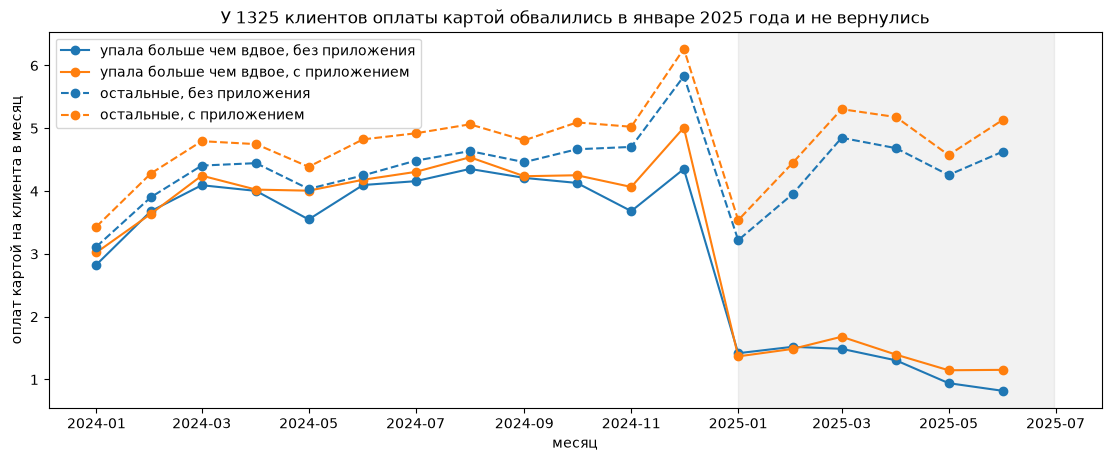

In [85]:
pay_m = pay[pay["client_id"].isin(profile.index)].merge(profile[["упала больше чем вдвое"]],
                                                        left_on="client_id", right_index=True)
traj = pay_m.groupby(["month", "упала больше чем вдвое", "has_mobile_app"]).size().unstack([1, 2])
traj = traj / profile.groupby(["упала больше чем вдвое", "has_mobile_app"]).size()

labels = {(True, False): "упала больше чем вдвое, без приложения", (True, True): "упала больше чем вдвое, с приложением",
          (False, False): "остальные, без приложения", (False, True): "остальные, с приложением"}
colors = {False: "tab:blue", True: "tab:orange"}
fig, ax = plt.subplots(figsize=(11, 4.5), layout="constrained")
for col, label in labels.items():
    ax.plot(traj.index.to_timestamp(), traj[col], marker="o", label=label, color=colors[col[1]],
            linestyle="-" if col[0] else "--")
ax.axvspan(pd.Timestamp("2025-01-01"), pd.Timestamp("2025-06-30"), color="grey", alpha=0.1)
ax.set_xlabel("месяц")
ax.set_ylabel("оплат картой на клиента в месяц")
ax.set_title(f"У {profile['упала больше чем вдвое'].sum()} клиентов оплаты картой обвалились в январе 2025 года и не вернулись")
ax.legend()
plt.show()

До конца 2024 года клиенты, у которых потом активность упала, вели себя почти так же, как остальные, с тем же декабрьским всплеском. В январе 2025 года их оплаты картой упали в несколько раз и больше не вернулись, а к июню опустились еще ниже. У остальных клиентов январь 2025 года – обычный сезонный провал, как в январе 2024 года, после которого активность возвращается. Значит, это не постепенное снижение, а резкий обвал в одном месяце, и с приложением и без него он выглядит одинаково.

Проверяем, не перешли ли эти клиенты на другой способ оплаты и не перестали ли они тратить на что-то одно. Для этого считаем изменение по каналам по всем успешным операциям и по категориям оплат картой. База делится на месяцы с открытой картой, как в разделе 6.

In [86]:
parts = []
for col, ops in [("channel", txn_ok), ("category", pay)]:
    x = (ops[ops["client_id"].isin(profile.index)]
         .groupby(["client_id", col, "period"]).size().unstack(fill_value=0).reset_index()
         .merge(profile[["месяцев в базе", "упала больше чем вдвое"]], left_on="client_id", right_index=True))
    x["base"] = x["base"] / x["месяцев в базе"]
    x["eval"] = x["eval"] / 6
    s = x.groupby([col, "упала больше чем вдвое"])[["base", "eval"]].sum()
    parts.append(((s["eval"] / s["base"] - 1) * 100).unstack())
by_kind = pd.concat(parts, keys=["канал (все операции)", "категория (оплаты картой)"]).round(2)
by_kind.columns = ["остальные, изменение %", "упала больше чем вдвое, изменение %"]
by_kind

остальные, изменение %  упала больше чем вдвое, изменение %
канал (все операции)      Карта                                -18.76                               -67.86
                          Онлайн-банк                           -8.55                               -56.75
                          СБП                                  -21.48                               -62.69
                          Токен                                 54.50                               -66.95
категория (оплаты картой) АЗС                                   -0.51                               -66.70
                          Аптеки                                -3.76                               -67.20
                          Кафе и рестораны                     -17.75                               -71.81
                          Одежда и обувь                        -0.10                               -65.85
                          Онлайн-сервисы                        -0.25                               -66.40
                          Продукты                              -1.30                               -68.11
                          Развлечения и досуг                    0.05                               -64.45
                          Связь и интернет                      -1.69                               -68.08
                          Транспорт                             -2.27                               -67.12

У клиентов с обвалом упали все каналы, от -56.75% у `Онлайн-банк` до -67.86% у `Карта`. `Токен` у них тоже упал, на 66.95%. Упали и все категории, от -64.45% до -71.81%. То есть они не перешли на `СБП` или `Онлайн-банк` и не отказались от чего-то одного, а почти перестали платить через наш банк. Похоже, что основные траты они перенесли в другой банк, но по нашим данным проверить это нельзя.
У остальных клиентов категории почти не изменились, от -3.76% до 0.05%, кроме `Кафе и рестораны`, где падение -17.75%. `Токен` у них вырос на 54.50%, а `Карта` упала на 18.76%, это переход на оплату телефоном из 5.4.

У остальных клиентов отдельно выделяется категория `Кафе и рестораны`. Проверяем, есть ли клиенты, которые почти перестали ходить в кафе, а остальные траты оставили. Правило такое. Клиент в 2024 году платил картой в кафе хотя бы раз в месяц, в 2025 году таких оплат стало меньше хотя бы на 80%, а оплаты в остальных категориях упали меньше чем на 20%. Если это случайные колебания, такое же правило даст похожую долю клиентов в любой категории, поэтому применяем его ко всем категориям. Доля считается от клиентов, которые платили в категории раз в месяц и чаще.

In [87]:
stable = profile[~profile["упала больше чем вдвое"]]
check = {}
for cat in pay["category"].unique():
    in_cat = pay["category"] == cat
    c = (pay[in_cat].groupby(["client_id", "period"]).size().unstack(fill_value=0)
         .reindex(stable.index, fill_value=0))
    o = (pay[~in_cat].groupby(["client_id", "period"]).size().unstack(fill_value=0)
         .reindex(stable.index, fill_value=0))
    cat_base = c["base"] / stable["месяцев в базе"]
    cat_change = (c["eval"] / 6 / cat_base - 1) * 100
    other_change = (o["eval"] / 6 / (o["base"] / stable["месяцев в базе"]) - 1) * 100
    regular = cat_base >= 1
    dropped = regular & (cat_change <= -80) & (other_change > -20)
    check[cat] = {"платили раз в месяц и чаще": regular.sum(), "почти перестали, остальное на месте": dropped.sum()}
check = pd.DataFrame(check).T
check["доля, %"] = (check["почти перестали, остальное на месте"] / check["платили раз в месяц и чаще"] * 100).round(1)
check.sort_values("доля, %", ascending=False)

,платили раз в месяц и чаще,"почти перестали, остальное на месте","доля, %"
Кафе и рестораны,909,188,20.7
Развлечения и досуг,222,8,3.6
Аптеки,113,4,3.5
Онлайн-сервисы,130,3,2.3
АЗС,342,7,2.0
Одежда и обувь,431,8,1.9
Связь и интернет,159,3,1.9
Транспорт,412,8,1.9
Продукты,2056,18,0.9


Для кафе правило выполняется у 188 клиентов из 909, это 20.7%. Для остальных категорий от 0.9% до 3.6%. Значит, отказ от кафе – это отдельное явление, а не случайные колебания. Эти клиенты не перестали пользоваться картой, они перестали платить ей в кафе и ресторанах.

Получилось два типа падения. Первый – резкий обвал оплат картой с января 2025 года по всем категориям и каналам. Второй – отказ от кафе при остальных тратах на месте. Из них составляем четыре группы.

**Группа 1.** Клиенты массового сегмента без мобильного приложения, у которых оплаты картой в 2025 году упали больше чем вдвое.

**Группа 2.** Клиенты массового сегмента с мобильным приложением, у которых оплаты картой в 2025 году упали больше чем вдвое.

**Группа 3.** Клиенты зарплатного, премиального и Private сегментов, у которых оплаты картой в 2025 году упали больше чем вдвое.

**Группа 4.** Клиенты, которые в 2024 году платили картой в кафе и ресторанах хотя бы раз в месяц, а в 2025 году почти перестали. Оплат в кафе стало меньше хотя бы на 80%, а остальные оплаты картой упали меньше чем на 20%.

Массовый сегмент делим по приложению, потому что с этими клиентами нужно связываться по-разному. Клиенту с приложением предложение можно показать в приложении, клиенту без приложения – только через SMS, звонок или в отделении. Остальные сегменты объединяем в одну группу, потому что обвал у них такой же, а премиальных и Private клиентов с ним слишком мало для отдельной группы.
В кампанию берем только клиентов с согласием на коммуникацию. Клиентов с конфликтующими записями в справочнике не берем, потому что у них две разные записи и неизвестно, какая из них верная (3.5).
Правило конфликтов. Группы 1–3 не пересекаются, потому что различаются сегментом и приложением, а в группу 4 попадают только клиенты без обвала. Если клиент все же подходит под несколько групп, его относим к первой подходящей по порядку номеров. Обвал ставим выше отказа от кафе, потому что при обвале клиент почти перестал пользоваться картой, а не одной категорией.

In [88]:
cand = profile[profile["marketing_opt_in"] & ~profile["conflict"]]
mass = cand["segment"] == "Массовый"
fell = cand["упала больше чем вдвое"]
cafe_drop = ((cand["кафе база, оп./мес."] >= 1) & (cand["кафе, изменение %"] <= -80)
             & (cand["без кафе, изменение %"] > -20))

group_names = ["1. массовый без приложения, обвал оплат",
               "2. массовый с приложением, обвал оплат",
               "3. зарплатный, премиальный и Private, обвал оплат",
               "4. перестали ходить в кафе"]
conditions = [fell & mass & ~cand["has_mobile_app"],
              fell & mass & cand["has_mobile_app"],
              fell & ~mass,
              ~fell & cafe_drop]
print("клиентов, подходящих больше чем под одну группу:", (sum(c.astype(int) for c in conditions) > 1).sum())
cand = cand.assign(group=np.select(conditions, group_names, default=""))
campaign = cand[cand["group"] != ""]
print("клиентов в кампании:", len(campaign), "| уникальных:", campaign.index.nunique())
print("группа 3 по сегментам:", campaign.loc[campaign["group"] == group_names[2], "segment"].value_counts().to_dict())
campaign["group"].value_counts().sort_index().to_frame("клиентов")

клиентов, подходящих больше чем под одну группу: 0
клиентов в кампании: 1353 | уникальных: 1353
группа 3 по сегментам: {'Зарплатный': 163, 'Премиальный': 79, 'Private': 22}


,клиентов
group,
"1. массовый без приложения, обвал оплат",473
"2. массовый с приложением, обвал оплат",448
"3. зарплатный, премиальный и Private, обвал оплат",264
4. перестали ходить в кафе,168


Ни один клиент не подходит больше чем под одну группу. В кампанию попадает 1353 клиента, все уникальные, это меньше лимита 2000. Самая маленькая группа 4, в ней 168 клиентов, это больше минимума 150. В группе 3 зарплатных клиентов 163, премиальных 79 и Private 22.

Описываем каждую группу и сравниваем с клиентами с метрикой, которые в кампанию не вошли. Среди них есть и клиенты без согласия на коммуникацию. Оплаты в месяц считаем как среднее на клиента в группе, а изменение по сумме метрики всех клиентов группы, как в разделе 6.

In [89]:
others = profile[~profile.index.isin(campaign.index)].assign(group="не вошли в кампанию")
both = pd.concat([campaign, others])
g = both.groupby("group")
groups = pd.DataFrame({
    "клиентов": g.size(),
    "база, оп./мес.": g["база, оп./мес."].mean(),
    "январь–июнь 2025, оп./мес.": g["оценка, оп./мес."].mean(),
    "апрель–июнь 2025, оп./мес.": g["апрель–июнь, оп./мес."].mean(),
    "кафе база, оп./мес.": g["кафе база, оп./мес."].mean(),
    "с приложением, %": g["has_mobile_app"].mean() * 100,
    "55+, %": g["age_group"].apply(lambda s: (s == "55+").mean() * 100),
})
groups["изменение, %"] = (groups["январь–июнь 2025, оп./мес."] / groups["база, оп./мес."] - 1) * 100
groups["апрель–июнь к базе, %"] = (groups["апрель–июнь 2025, оп./мес."] / groups["база, оп./мес."] - 1) * 100
cafe_e = (both["кафе база, оп./мес."] * (1 + both["кафе, изменение %"] / 100)).fillna(0)
groups["кафе, изменение %"] = (cafe_e.groupby(both["group"]).sum() / g["кафе база, оп./мес."].sum() - 1) * 100
groups.round(2).T

group,"1. массовый без приложения, обвал оплат","2. массовый с приложением, обвал оплат","3. зарплатный, премиальный и Private, обвал оплат",4. перестали ходить в кафе,не вошли в кампанию
клиентов,473.00,448.00,264.00,168.00,3691.00
"база, оп./мес.",3.85,4.19,4.26,6.99,4.59
"январь–июнь 2025, оп./мес.",1.20,1.34,1.45,5.20,4.40
"апрель–июнь 2025, оп./мес.",0.94,1.20,1.30,5.60,4.64
"кафе база, оп./мес.",0.39,0.43,0.71,1.92,0.64
"с приложением, %",0.00,100.00,46.21,57.74,65.70
"55+, %",56.87,36.16,54.92,41.67,40.29
"изменение, %",-68.92,-67.95,-66.05,-25.60,-4.13
"апрель–июнь к базе, %",-75.52,-71.39,-69.53,-19.82,1.14
"кафе, изменение %",-71.09,-70.37,-74.19,-93.32,-10.35


**Группа 1, 473 клиента.** В 2024 году 3.85 оплаты картой в месяц, в январе–июне 2025 года 1.20, падение -68.92%. В апреле–июне уже -75.52% к базе, то есть активность продолжает угасать и к концу периода почти сошла на нет. Клиентов 55+ здесь 56.87%, больше, чем в других группах. Падение за счет того, что с января 2025 года клиенты почти перестали платить через банк, во всех категориях и каналах. Связаться с ними можно только через SMS, звонок или отделение.

**Группа 2, 448 клиентов.** 4.19 оплаты в месяц в базе и 1.34 в 2025 году, падение -67.95%, в апреле–июне -71.39%. Обвал такой же, как в группе 1, хотя приложение есть у всех. Это не переход на оплату телефоном, потому что токен у клиентов с обвалом тоже упал. С ними можно связаться через приложение.

**Группа 3, 264 клиента.** 4.26 оплаты в месяц в базе и 1.45 в 2025 году, падение -66.05%, в апреле–июне -69.53%. Тот же обвал, но у клиентов старших сегментов, которые для банка ценнее всего. Больше всего здесь зарплатных клиентов. Возможно, у части из них зарплата теперь приходит в другой банк, но в данных этого не видно.

**Группа 4, 168 клиентов.** Самые активные клиенты, 6.99 оплаты картой в месяц в базе, из них 1.92 в кафе. Оплаты в кафе упали на 93.32%, а все оплаты картой на 25.60%, то есть падение почти целиком за счет кафе. Остальные траты на месте, поэтому им стоит предлагать что-то связанное с кафе и ресторанами, например повышенный кешбэк.

Причины падения у клиентов пересекаются. У групп 1–3 оплаты в кафе тоже упали, на 70.37–74.19%, но вместе со всеми остальными тратами, поэтому эти клиенты относятся к обвалу, а не к отказу от кафе. Так и работает правило конфликтов.
У клиентов, которые не вошли в кампанию, оплаты картой почти не изменились, -4.13%.

### 7.1. Кого в кампанию не берём и почему

Считаем, кто не попал в кампанию и почему. Причины проверяем по порядку, и каждого клиента относим к первой подходящей, поэтому сумма сходится с общим числом клиентов в данных.

In [90]:
rest = profile[~profile.index.isin(campaign.index)]
no_consent = ~rest["marketing_opt_in"]
conflict_only = rest["marketing_opt_in"] & rest["conflict"]
other = rest[rest["marketing_opt_in"] & ~rest["conflict"]]

excluded = pd.Series({
    "ушли из банка, нет в справочнике": len(unknown_ids),
    "нет базы для метрики (раздел 6)": funnel["клиентов в справочнике"] - funnel["остается для метрики"],
    "нет согласия на коммуникацию": no_consent.sum(),
    "конфликтующие записи в справочнике": conflict_only.sum(),
    "активность не упала": (other["изменение, %"] >= 0).sum(),
    "упала меньше чем вдвое и не за счет кафе": (other["изменение, %"] < 0).sum(),
}).to_frame("клиентов")
print("в кампании:", len(campaign))
print("всего клиентов в данных:", excluded["клиентов"].sum() + len(campaign), "=", len(clients), "+", len(unknown_ids))
print("свободных мест в бюджете:", 2000 - len(campaign))
print("без согласия, но с обвалом оплат:", rest.loc[no_consent, "упала больше чем вдвое"].sum())
excluded

в кампании: 1353
всего клиентов в данных: 6000 = 5635 + 365
свободных мест в бюджете: 647
без согласия, но с обвалом оплат: 140


,клиентов
"ушли из банка, нет в справочнике",365
нет базы для метрики (раздел 6),591
нет согласия на коммуникацию,578
конфликтующие записи в справочнике,12
активность не упала,1387
упала меньше чем вдвое и не за счет кафе,1714


Всего в данных 6000 клиентов, 5635 в справочнике и 365 только в операциях. В кампанию попадает 1353, остальных не берем по таким причинам:

- 365 клиентов, судя по всему, ушли из банка. Их нет в справочнике действующих клиентов, а последняя операция у них в конце 2024 – начале 2025 года (2.4). Возвращать ушедших клиентов – это другая задача, не наша кампания.
- У 591 клиента нет базы. Карта у них открыта после сентября 2024 года или в 2024 году не было ни одной оплаты картой, поэтому падение посчитать нельзя.
- 578 клиентов не дали согласия на коммуникацию, а без него связываться с клиентом нельзя по условию. Среди них 140 клиентов с обвалом оплат. Банк их теряет, но обратиться к ним кампанией не может.
- У 12 клиентов в справочнике две записи с разным сегментом или городом. Нельзя точно сказать, в какую группу они попадают, поэтому их тоже не берем.
- У 1387 клиентов активность не упала, возвращать нечего.
- У 1714 клиентов активность упала, но меньше чем вдвое и не за счет кафе. Почему их не берем, смотрим ниже.

Смотрим, как сильно и у каких сегментов упала активность у клиентов с умеренным падением.

In [91]:
moderate = other[other["изменение, %"] < 0]
mod_seg = moderate.groupby("segment")[["база, оп./мес.", "оценка, оп./мес."]].sum()
mod_seg["изменение, %"] = (mod_seg["оценка, оп./мес."] / mod_seg["база, оп./мес."] - 1) * 100
mod_seg["клиентов"] = moderate.groupby("segment").size()
mod_seg["медиана изменения, %"] = moderate.groupby("segment")["изменение, %"].median()
mod_seg[["клиентов", "изменение, %", "медиана изменения, %"]].round(2)

,клиентов,"изменение, %","медиана изменения, %"
segment,,,
Private,91,-21.45,-21.74
Зарплатный,479,-19.83,-20.00
Массовый,863,-23.51,-25.00
Премиальный,281,-20.73,-20.00


Умеренное падение примерно одинаковое во всех сегментах, медиана изменения от -20.00% до -25.00%. Часть его объясняется сезонностью. Базовое окно включает декабрьский всплеск, а если сравнивать с теми же месяцами 2024 года, у зарплатного и премиального сегментов падения нет совсем. Общей причины, как у групп 1–4, у этих клиентов не видно, поэтому непонятно, что им предлагать. Бюджет позволяет взять еще 647 клиентов, но группа без понятной причины падения задачу заказчика не решает.

## 8. Что проверили и что не подтвердилось

Гипотезы, которые вы проверили и отвергли. По одной строке на гипотезу,
с числом.

## 9. Сохранение результатов

Три файла: очищенная таблица для второго ноутбука, журнал изменений,
итоговый список кампании.

In [92]:
# clean.to_parquet("clean_data.parquet", index=False)
# cleaning_log.to_csv("cleaning_log.csv", index=False, encoding="utf-8")
# campaign[["client_id", "group"]].to_csv("campaign_list.csv", index=False, encoding="utf-8")